# AIC 2026 — Textual KIS Query Retrieval → Submission

Notebook này là **online/query-time stage độc lập**. Nó **không** build lại master, normalize objects, Qwen corpus embeddings hay FAISS.

## Input artifacts đã có

```text
/content/drive/MyDrive/data/
├── processed-objects/
│   ├── objects_index.parquet
│   └── keyframe_object_summary.parquet
└── retrieval-artifacts/
    ├── master_keyframes.parquet
    ├── qwen3_vl_embedding_1024d.npy
    ├── qwen3_vl_embedding_1024d.manifest.json
    ├── qwen3_vl_1024d.index
    └── qwen3_vl_1024d.index.meta.json
```

## Online pipeline

```text
query-*-kis.txt
    ↓
Query parser / faithful variants
    ↓
Qwen3-VL-Embedding-2B text embedding
    ↓
FAISS exact retrieval × variants
    ↓
Weighted RRF
    ↓
Base-object score + BM25 lexical score
    ↓
Grounding DINO query-time verification
    ↓
Lazy OCR only when literal visible text is requested
    ↓
Temporal grouping by video_id + pts_time
    ↓
Qwen3-VL-Reranker-2B on neighbor keyframes
    ↓
Diversity-aware Top-100
    ↓
submission/query-*-kis.csv
    ↓
AIC2026Submission.zip
```

### Competition output rules implemented here

- CSV UTF-8, comma delimiter.
- **No header**.
- Each line: `video_id,frame_idx`.
- `video_id` has no `.mp4`.
- `frame_idx` is integer.
- Maximum 100 rows/query.
- ZIP contains the **`submission/` directory**, not loose CSV files.
- If `media_index.parquet` is absent, video-level metadata is lazily rebuilt from `media-info/`.
- Every run stores its config, query texts, Top-500 candidates and segment diagnostics for reproducibility.

> Recommended runtime: Colab Pro + A100. The notebook only copies the relatively small set of query-time candidate images to local `/content`; it does not extract the full keyframe corpus again.


In [1]:
# ============================================================
# 0. INSTALL
# ============================================================
# Keep the Colab CUDA/PyTorch stack. Do not reinstall torch.
# Do not force-upgrade Pillow; previous sessions showed Pillow hot-upgrade can break PIL internals.

!pip -q install -U \
    "transformers>=4.57.3,<5" \
    "accelerate>=1.12.0" \
    "qwen-vl-utils>=0.0.14" \
    huggingface_hub \
    faiss-cpu \
    pyarrow \
    rank-bm25 \
    rapidfuzz \
    unidecode \
    easyocr \
    scipy \
    sentencepiece

!rm -rf /content/Qwen3-VL-Embedding
!git clone -q --depth 1 https://github.com/QwenLM/Qwen3-VL-Embedding.git /content/Qwen3-VL-Embedding

print("Dependencies installed.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 111.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 107.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 44.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 81.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97

In [7]:
# ============================================================
# 1. MOUNT DRIVE + GLOBAL CONFIG
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import os, sys, gc, json, math, re, hashlib, shutil, zipfile, subprocess, unicodedata, warnings

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from PIL import Image
from IPython.display import display

# ROOT = Path('/content/drive/MyDrive/data')
ROOT = Path('/content/drive/MyDrive/AI Challenge/data')

KEYFRAME_DIR = ROOT / 'keyframes'
MEDIA_DIR = ROOT / 'media-info'
PROCESSED_OBJECTS_DIR = ROOT / 'processed-objects'
ARTIFACT_DIR = ROOT / 'retrieval-artifacts'

MASTER_PATH = ARTIFACT_DIR / 'master_keyframes.parquet'
QWEN_MANIFEST_PATH = ARTIFACT_DIR / 'qwen3_vl_embedding_1024d.manifest.json'
FAISS_PATH = ARTIFACT_DIR / 'qwen3_vl_1024d.index'
FAISS_META_PATH = ARTIFACT_DIR / 'qwen3_vl_1024d.index.meta.json'
OBJECT_INDEX_PATH = PROCESSED_OBJECTS_DIR / 'objects_index.parquet'
OBJECT_SUMMARY_PATH = PROCESSED_OBJECTS_DIR / 'keyframe_object_summary.parquet'
MEDIA_INDEX_PATH = ARTIFACT_DIR / 'media_index.parquet'

QWEN_REPO_DIR = Path('/content/Qwen3-VL-Embedding')
QWEN_MODEL_ID = 'Qwen/Qwen3-VL-Embedding-2B'
QWEN_RERANKER_ID = 'Qwen/Qwen3-VL-Reranker-2B'
PARSER_MODEL_ID = 'Qwen/Qwen2.5-0.5B-Instruct'
GROUNDING_DINO_ID = 'IDEA-Research/grounding-dino-tiny'

INDEX_DIM = 1024
QWEN_MIN_PIXELS = 32 * 32
QWEN_MAX_PIXELS = 768 * 768
QWEN_MAX_LENGTH = 4096
RETRIEVAL_INSTRUCTION = 'Retrieve video keyframes that visually match the user event description.'
RERANK_INSTRUCTION = 'Rank video-keyframe segments by how completely their visual content matches the textual event description.'

# -------- Retrieval depth --------
TOPK_PER_VARIANT = 1500
TOPK_AFTER_FUSION = 1500
RRF_K = 60
EXPENSIVE_VERIFY_TOPK = 160
OCR_TOPK = 100
TEMPORAL_INPUT_TOPK = 800
RERANK_TOP_SEGMENTS = 50
TEMPORAL_GAP_SECONDS = 12.0
MAX_RESULTS = 100

# -------- Score initialization; tune on validation --------
PRE_RERANK_WEIGHTS = {
    'retrieval_score': 0.60,
    'base_object_score': 0.10,
    'grounding_score': 0.18,
    'metadata_score': 0.07,
    'ocr_score': 0.05,
}
RERANK_RETRIEVAL_WEIGHT = 0.45
RERANK_MODEL_WEIGHT = 0.55

# -------- Stage profiles --------
PROFILES = {
    'BASE_QWEN': {
        'parser': False, 'base_object': False, 'bm25': False,
        'grounding': False, 'ocr': False, 'reranker': False,
    },
    'FUSION': {
        'parser': True, 'base_object': True, 'bm25': True,
        'grounding': False, 'ocr': False, 'reranker': False,
    },
    'FULL': {
        'parser': True, 'base_object': True, 'bm25': True,
        'grounding': True, 'ocr': True, 'reranker': True,
    },
}
RUN_PROFILE = 'FULL'

# -------- Query / output directories --------
# Put official *.txt query files in ONE of these locations.
QUERY_DIR_CANDIDATES = [
    Path('/content/queries'),
    ROOT / 'queries',
    ROOT / 'query-packages' / 'current',
]

LOCAL_ROOT = Path('/content/aic-textual-kis-query')
LOCAL_IMAGE_CACHE = LOCAL_ROOT / 'candidate-images'
LOCAL_RUN_ROOT = LOCAL_ROOT / 'runs'
DRIVE_RUN_ROOT = ARTIFACT_DIR / 'query-runs'
GROUNDING_CACHE_DIR = PROCESSED_OBJECTS_DIR / 'grounding-cache'
OCR_CACHE_DIR = ARTIFACT_DIR / 'ocr-cache'

for p in [LOCAL_IMAGE_CACHE, LOCAL_RUN_ROOT, DRIVE_RUN_ROOT, GROUNDING_CACHE_DIR, OCR_CACHE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

HF_CACHE = ROOT / '.hf-cache'
HF_CACHE.mkdir(parents=True, exist_ok=True)
os.environ['HF_HOME'] = str(HF_CACHE)
os.environ['HF_HUB_CACHE'] = str(HF_CACHE / 'hub')

SUBMISSION_ZIP_NAME = 'AIC2026Submission.zip'  # alphanumeric basename as recommended by BTC

DTYPE = torch.float32
if torch.cuda.is_available():
    DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('dtype:', DTYPE)
print('profile:', RUN_PROFILE, PROFILES[RUN_PROFILE])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA A100-SXM4-40GB
dtype: torch.bfloat16
profile: FULL {'parser': True, 'base_object': True, 'bm25': True, 'grounding': True, 'ocr': True, 'reranker': True}


## 2. Optional: upload official query files directly to Colab

Nếu bạn đã đặt các file vào `MyDrive/data/queries/` thì **bỏ qua cell này**.

Nếu muốn upload trực tiếp từ máy, chạy cell dưới. File sẽ được ghi vào `/content/queries/`.


In [8]:
# OPTIONAL CELL — uncomment the last line when needed.
def upload_query_files():
    from google.colab import files
    target = Path('/content/queries')
    target.mkdir(parents=True, exist_ok=True)
    uploaded = files.upload()
    for name, data in uploaded.items():
        p = target / Path(name).name
        p.write_bytes(data)
        print('Saved:', p)
    return target

# QUERY_DIR = upload_query_files()


In [10]:
# ============================================================
# 3. JSON + FINGERPRINT HELPERS
# ============================================================
def read_json(path, default=None):
    path = Path(path)
    if not path.exists():
        return default
    return json.loads(path.read_text(encoding='utf-8'))


def atomic_write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
    os.replace(tmp, path)


def compute_master_fingerprint(df):
    cols = ['global_id', 'video_id', 'keyframe_id', 'image_path', 'frame_idx', 'pts_time']
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f'Cannot fingerprint master; missing={missing}')
    hashed = pd.util.hash_pandas_object(df[cols], index=False).to_numpy(dtype=np.uint64)
    return hashlib.sha256(hashed.tobytes()).hexdigest()


def normalize_text(text):
    if text is None:
        return ''
    if isinstance(text, float) and np.isnan(text):
        return ''
    text = unicodedata.normalize('NFC', str(text)).replace('\x00', ' ')
    return re.sub(r'\s+', ' ', text).strip()


def norm_key(text):
    from unidecode import unidecode
    text = unidecode(normalize_text(text).lower())
    return re.sub(r'[^a-z0-9]+', ' ', text).strip()


In [11]:
# ============================================================
# 4. LOAD + VALIDATE MASTER / MANIFEST / FAISS
# ============================================================
import faiss

for p in [MASTER_PATH, QWEN_MANIFEST_PATH, FAISS_PATH, FAISS_META_PATH]:
    assert p.exists(), f'Missing required artifact: {p}'

master = pd.read_parquet(MASTER_PATH)
master = master.sort_values('global_id').reset_index(drop=True)

required_cols = {'global_id', 'video_id', 'keyframe_id', 'image_path', 'frame_idx', 'pts_time'}
missing = required_cols - set(master.columns)
assert not missing, f'Master missing columns: {missing}'

master['global_id'] = pd.to_numeric(master['global_id'], errors='raise').astype(np.int64)
master['frame_idx'] = pd.to_numeric(master['frame_idx'], errors='raise').astype(np.int64)
master['pts_time'] = pd.to_numeric(master['pts_time'], errors='coerce')
master['video_id'] = master['video_id'].astype(str)
master['keyframe_id'] = master['keyframe_id'].astype(str)

N = len(master)
assert master['global_id'].is_unique
assert np.array_equal(master['global_id'].to_numpy(), np.arange(N, dtype=np.int64)), \
    'global_id != row index; DO NOT query this FAISS index until mapping is fixed.'

manifest = read_json(QWEN_MANIFEST_PATH, {})
faiss_meta = read_json(FAISS_META_PATH, {})
MASTER_FINGERPRINT = compute_master_fingerprint(master)

for meta_name, meta in [('manifest', manifest), ('faiss_meta', faiss_meta)]:
    fp = meta.get('master_fingerprint')
    if fp:
        assert fp == MASTER_FINGERPRINT, f'{meta_name} master fingerprint mismatch'

assert manifest.get('model', QWEN_MODEL_ID) == QWEN_MODEL_ID
assert int(manifest.get('index_dim', INDEX_DIM)) == INDEX_DIM
if manifest.get('retrieval_instruction'):
    assert manifest['retrieval_instruction'] == RETRIEVAL_INSTRUCTION

faiss_index = faiss.read_index(str(FAISS_PATH))
assert faiss_index.ntotal == N, (faiss_index.ntotal, N)
assert faiss_index.d == INDEX_DIM, (faiss_index.d, INDEX_DIM)

print(f'Master rows : {N:,}')
print(f'Videos      : {master.video_id.nunique():,}')
print('Columns     :', len(master.columns))
print('Fingerprint :', MASTER_FINGERPRINT)
print('FAISS       :', type(faiss_index).__name__, '| ntotal=', faiss_index.ntotal, '| d=', faiss_index.d)
print('Object fields present:', [c for c in ['objects_json','object_labels','object_search_text'] if c in master.columns])
print('Text fields present  :', [c for c in ['lexical_text','semantic_metadata_text','asr_context_text','ocr_text'] if c in master.columns])


Master rows : 177,321
Videos      : 873
Columns     : 33
Fingerprint : 6e9f6626b8cd1c1223d3ece8fd8cf33509f76d30d2cbd4af029d7d4544eee9c9
FAISS       : IndexFlatIP | ntotal= 177321 | d= 1024
Object fields present: ['objects_json', 'object_labels', 'object_search_text']
Text fields present  : ['lexical_text', 'semantic_metadata_text', 'asr_context_text', 'ocr_text']


In [12]:
# ============================================================
# 5. PIN QWEN REPO TO EMBEDDING COMMIT WHEN AVAILABLE
# ============================================================
# This reduces the risk that a fresh query session uses different local model wrapper code
# from the wrapper used to create the corpus embeddings.

embedding_commit = manifest.get('qwen_repo_commit')
print('Embedding repo commit:', embedding_commit)

if embedding_commit and embedding_commit != 'unknown':
    try:
        subprocess.run(
            ['git', '-C', str(QWEN_REPO_DIR), 'fetch', '--depth', '1', 'origin', embedding_commit],
            check=False, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True,
        )
        subprocess.run(
            ['git', '-C', str(QWEN_REPO_DIR), 'checkout', '--detach', embedding_commit],
            check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True,
        )
        print('Checked out exact embedding commit.')
    except Exception as e:
        warnings.warn(f'Could not checkout exact commit; using cloned repo HEAD. Reason: {e}')

try:
    current_commit = subprocess.check_output(
        ['git', '-C', str(QWEN_REPO_DIR), 'rev-parse', 'HEAD'], text=True
    ).strip()
except Exception:
    current_commit = 'unknown'

print('Query repo commit:', current_commit)


Embedding repo commit: 393e2978d27852b0d0230d6994f37f9c15bed73c
Checked out exact embedding commit.
Query repo commit: 393e2978d27852b0d0230d6994f37f9c15bed73c


In [13]:
# ============================================================
# 6. IMAGE PATH RESOLUTION + LOCAL LAZY CACHE
# ============================================================
_IMAGE_EXTS = ['.jpg', '.jpeg', '.png', '.webp']


def row_from_gid(gid):
    return master.iloc[int(gid)]


def resolve_source_image(row):
    p = Path(str(row.image_path))
    if p.exists():
        return p

    # Fallback for a relocated Drive mount or stale absolute prefix.
    video_id = str(row.video_id)
    kf = str(row.keyframe_id)
    for ext in _IMAGE_EXTS:
        cand = KEYFRAME_DIR / video_id / f'{kf}{ext}'
        if cand.exists():
            return cand

    # Last resort: use basename under expected video directory.
    basename = p.name
    cand = KEYFRAME_DIR / video_id / basename
    if cand.exists():
        return cand

    raise FileNotFoundError(f'Cannot resolve keyframe image for gid={int(row.global_id)}: {p}')


def materialize_gid(gid):
    row = row_from_gid(gid)
    src = resolve_source_image(row)
    dst_dir = LOCAL_IMAGE_CACHE / str(row.video_id)
    dst_dir.mkdir(parents=True, exist_ok=True)
    dst = dst_dir / src.name
    if not dst.exists() or dst.stat().st_size != src.stat().st_size:
        shutil.copy2(src, dst)
    return str(dst)


# Build robust per-video ordered gid arrays for temporal neighbors.
_video_gids = {}
for vid, g in master.sort_values(['video_id', 'pts_time', 'global_id']).groupby('video_id', sort=False):
    _video_gids[str(vid)] = g['global_id'].astype(int).tolist()
_gid_pos = {gid: i for vid, gids in _video_gids.items() for i, gid in enumerate(gids)}


def neighbor_gids(gid, radius=1):
    gid = int(gid)
    row = row_from_gid(gid)
    gids = _video_gids[str(row.video_id)]
    pos = _gid_pos[gid]
    lo = max(0, pos - int(radius))
    hi = min(len(gids), pos + int(radius) + 1)
    return gids[lo:hi]


def neighbor_rows(gid, radius=1):
    return master.iloc[neighbor_gids(gid, radius)].copy()

# Smoke-check a few paths without traversing the whole Drive tree.
for gid in [0, N // 2, N - 1]:
    print(gid, '->', resolve_source_image(row_from_gid(gid)))


0 -> /content/drive/MyDrive/AI Challenge/data/keyframes/L21_V001/001.jpg
88660 -> /content/drive/MyDrive/AI Challenge/data/keyframes/L26_V171/145.jpg
177320 -> /content/drive/MyDrive/AI Challenge/data/keyframes/L30_V096/084.jpg


In [14]:
# ============================================================
# 7. LOAD QWEN3-VL EMBEDDER + QUERY ENCODING
# ============================================================
sys.path.insert(0, str(QWEN_REPO_DIR))
from src.models.qwen3_vl_embedding import Qwen3VLEmbedder


def l2_normalize_np(x):
    x = np.asarray(x, dtype=np.float32)
    if x.ndim == 1:
        x = x[None, :]
    norms = np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-12)
    return x / norms


def to_mrl_dim(vec_tensor, dim=INDEX_DIM):
    vec = vec_tensor.detach().float().cpu().numpy()
    assert vec.ndim == 2 and vec.shape[1] >= dim
    return l2_normalize_np(vec[:, :dim]).astype(np.float32, copy=False)


embedder = Qwen3VLEmbedder(
    model_name_or_path=QWEN_MODEL_ID,
    max_length=QWEN_MAX_LENGTH,
    min_pixels=QWEN_MIN_PIXELS,
    max_pixels=QWEN_MAX_PIXELS,
    torch_dtype=DTYPE,
)


def encode_text_queries(texts):
    texts = [normalize_text(t) for t in texts]
    if any(not t for t in texts):
        raise ValueError('Empty query variant.')
    inputs = [
        {'text': t, 'instruction': RETRIEVAL_INSTRUCTION}
        for t in texts
    ]
    with torch.inference_mode():
        full = embedder.process(inputs, normalize=True)
    vec = to_mrl_dim(full, INDEX_DIM)
    faiss.normalize_L2(vec)
    return vec

# Text-only preflight against the already-built corpus index.
_preflight_q = encode_text_queries(['một người đang đứng ngoài trời'])
assert _preflight_q.shape == (1, INDEX_DIM)
assert np.allclose(np.linalg.norm(_preflight_q, axis=1), 1.0, atol=1e-4)
print('Qwen query encoder: OK', _preflight_q.shape)


`torch_dtype` is deprecated! Use `dtype` instead!


Qwen query encoder: OK (1, 1024)


## 8. Query parser

Parser chỉ tạo **faithful retrieval views**; prompt cấm thêm object/attribute/event không có trong query.

- `english_query`: dịch trung thành sang English.
- `visual_query`: mô tả ngắn tập trung vào thứ có thể nhìn thấy.
- `object_terms`: danh từ object nguyên tử để tận dụng Faster R-CNN object summary.
- `grounding_phrases`: phrase open-vocabulary có object + attribute/relation khi cần.
- `ocr_terms`: **chỉ** literal text/logo/number mà query yêu cầu nhìn thấy.
- `scene_terms`, `action_terms`: scene/action được nói rõ trong query.

Nếu parser lỗi/OOM, pipeline fallback về query gốc và vẫn chạy được.


In [15]:
# ============================================================
# 8. LOCAL QUERY PARSER
# ============================================================
from transformers import AutoTokenizer, AutoModelForCausalLM

_parser_tok = None
_parser_model = None


def fallback_parsed(query):
    return {
        'english_query': normalize_text(query),
        'visual_query': normalize_text(query),
        'object_terms': [],
        'grounding_phrases': [],
        'ocr_terms': [],
        'scene_terms': [],
        'action_terms': [],
    }


def load_parser():
    global _parser_tok, _parser_model
    if _parser_model is not None:
        return
    _parser_tok = AutoTokenizer.from_pretrained(PARSER_MODEL_ID)
    _parser_model = AutoModelForCausalLM.from_pretrained(
        PARSER_MODEL_ID,
        torch_dtype=DTYPE if torch.cuda.is_available() else torch.float32,
        device_map='auto' if torch.cuda.is_available() else None,
    )
    _parser_model.eval()


def unload_parser():
    global _parser_tok, _parser_model
    _parser_tok = None
    _parser_model = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def parse_json_loose(text):
    m = re.search(r'\{.*\}', text, flags=re.S)
    if not m:
        return None
    try:
        return json.loads(m.group(0))
    except Exception:
        return None


def _clean_str_list(value, max_items=10):
    if not isinstance(value, list):
        return []
    out = []
    seen = set()
    for x in value:
        s = normalize_text(x)
        k = norm_key(s)
        if s and k and k not in seen:
            seen.add(k)
            out.append(s)
        if len(out) >= max_items:
            break
    return out


def parse_query_local_llm(query, use_llm=True):
    query = normalize_text(query)
    fallback = fallback_parsed(query)
    if not use_llm:
        return fallback

    try:
        load_parser()
        prompt = f"""You are a strict query parser for text-to-video-keyframe retrieval.\n\
Return ONE JSON object only. Do not add facts that are not explicitly stated.\n\
Schema:\n\
{{\n\
  "english_query": "faithful English translation",\n\
  "visual_query": "short faithful visual description",\n\
  "object_terms": ["atomic visible nouns in English, preferably common detector categories"],\n\
  "grounding_phrases": ["visible object/attribute/relation phrases in English, directly supported by query"],\n\
  "ocr_terms": ["ONLY literal written text/logo/number that must be visible"],\n\
  "scene_terms": ["explicit scene/place concepts in English"],\n\
  "action_terms": ["explicit actions/events in English"]\n\
}}\n\
Rules:\n\
- Preserve colors, counts, clothing, spatial relations and actions when explicitly stated.\n\
- Do not infer identities, brands, objects, colors, locations or actions.\n\
- object_terms must be atomic nouns, not full sentences.\n\
- OCR terms are empty unless the query explicitly asks for visible written content/logo/number.\n\
- Maximum 8 items per list.\n\
Query: {query}"""

        messages = [
            {'role': 'system', 'content': 'Return valid JSON only.'},
            {'role': 'user', 'content': prompt},
        ]
        text = _parser_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = _parser_tok(text, return_tensors='pt').to(_parser_model.device)
        with torch.inference_mode():
            ids = _parser_model.generate(
                **inputs,
                max_new_tokens=320,
                do_sample=False,
                pad_token_id=_parser_tok.eos_token_id,
            )
        gen = ids[0, inputs['input_ids'].shape[1]:]
        raw = _parser_tok.decode(gen, skip_special_tokens=True)
        parsed = parse_json_loose(raw)
        if not isinstance(parsed, dict):
            return fallback

        result = {
            'english_query': normalize_text(parsed.get('english_query')) or query,
            'visual_query': normalize_text(parsed.get('visual_query')) or query,
            'object_terms': _clean_str_list(parsed.get('object_terms')),
            'grounding_phrases': _clean_str_list(parsed.get('grounding_phrases')),
            'ocr_terms': _clean_str_list(parsed.get('ocr_terms')),
            'scene_terms': _clean_str_list(parsed.get('scene_terms')),
            'action_terms': _clean_str_list(parsed.get('action_terms')),
        }
        return result
    except Exception as e:
        warnings.warn(f'Query parser fallback: {e}')
        return fallback


In [16]:
# ============================================================
# 9. QUERY VARIANTS + WEIGHTED RRF
# ============================================================
def build_query_variants(query, parsed):
    candidates = [
        ('original', normalize_text(query), 1.00),
        ('english', normalize_text(parsed.get('english_query')), 0.95),
        ('visual', normalize_text(parsed.get('visual_query')), 0.90),
    ]

    concept_parts = []
    for key in ['grounding_phrases', 'scene_terms', 'action_terms']:
        concept_parts.extend(parsed.get(key, []) or [])
    concept_text = ', '.join(dict.fromkeys(normalize_text(x) for x in concept_parts if normalize_text(x)))
    if concept_text:
        candidates.append(('concepts', concept_text, 0.75))

    out = []
    seen = set()
    for name, text, weight in candidates:
        key = norm_key(text)
        if not key or key in seen:
            continue
        seen.add(key)
        out.append({'name': name, 'text': text, 'weight': float(weight)})
    return out[:4]


def robust_minmax(values, lo_pct=2, hi_pct=98):
    x = np.asarray(values, dtype=np.float32)
    if len(x) == 0:
        return x
    lo, hi = np.percentile(x, [lo_pct, hi_pct]) if len(x) > 2 else (x.min(), x.max())
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo + 1e-8:
        return np.zeros_like(x)
    return np.clip((x - lo) / (hi - lo), 0.0, 1.0)


def multi_query_retrieve(query, parsed, topk_per_variant=TOPK_PER_VARIANT, topk_after=TOPK_AFTER_FUSION):
    variants = build_query_variants(query, parsed)
    texts = [v['text'] for v in variants]
    qvecs = encode_text_queries(texts)

    rows = []
    for v, qvec in zip(variants, qvecs):
        scores, ids = faiss_index.search(qvec[None, :].astype(np.float32), int(topk_per_variant))
        scores, ids = scores[0], ids[0]
        valid = ids >= 0
        scores, ids = scores[valid], ids[valid]
        for rank, (gid, score) in enumerate(zip(ids.tolist(), scores.tolist()), 1):
            rows.append({
                'global_id': int(gid),
                'variant': v['name'],
                'variant_weight': float(v['weight']),
                'variant_rank': int(rank),
                'qwen_score_variant': float(score),
                'rrf_part': float(v['weight']) / (RRF_K + rank),
            })

    hits = pd.DataFrame(rows)
    agg = hits.groupby('global_id', as_index=False).agg(
        rrf_raw=('rrf_part', 'sum'),
        qwen_score=('qwen_score_variant', 'max'),
        variant_hits=('variant', 'nunique'),
        best_variant_rank=('variant_rank', 'min'),
    )
    agg['rrf_norm'] = agg['rrf_raw'] / max(float(agg['rrf_raw'].max()), 1e-12)
    agg['qwen_norm'] = robust_minmax(agg['qwen_score'].to_numpy())
    agg['retrieval_score'] = 0.85 * agg['rrf_norm'] + 0.15 * agg['qwen_norm']
    agg = agg.sort_values(['retrieval_score', 'qwen_score'], ascending=False).head(topk_after).reset_index(drop=True)

    result = master.iloc[agg['global_id'].astype(int).to_numpy()].copy().reset_index(drop=True)
    result = result.merge(agg, on='global_id', how='left', validate='one_to_one')
    result = result.sort_values('retrieval_score', ascending=False).reset_index(drop=True)
    return result, variants, hits


In [17]:
# ============================================================
# 10. BASE OBJECT SCORE FROM objects_json
# ============================================================
from rapidfuzz.fuzz import ratio


def parse_objects_json(value):
    if isinstance(value, dict):
        return value
    if value is None:
        return {}
    try:
        return json.loads(value)
    except Exception:
        return {}


def fuzzy_label_similarity(term, label):
    a, b = norm_key(term), norm_key(label)
    if not a or not b:
        return 0.0
    if a == b or a in b or b in a:
        return 1.0
    return ratio(a, b) / 100.0


def base_object_score_one(objects_json, object_terms):
    terms = [t for t in object_terms if norm_key(t)]
    if not terms:
        return 0.0
    data = parse_objects_json(objects_json)
    if not data:
        return 0.0

    best_scores = []
    matched = 0
    for term in terms:
        best = 0.0
        for label, info in data.items():
            sim = fuzzy_label_similarity(term, label)
            if sim < 0.55:
                continue
            info = info if isinstance(info, dict) else {}
            conf = float(info.get('max_conf', 0.5) or 0.0)
            area = float(info.get('max_area', 0.0) or 0.0)
            area_term = min(1.0, math.sqrt(max(area, 0.0) / 0.25)) if area > 0 else 0.25
            evidence = sim * (0.72 * np.clip(conf, 0, 1) + 0.28 * area_term)
            best = max(best, float(evidence))
        best_scores.append(best)
        matched += int(best >= 0.35)

    mean_best = float(np.mean(best_scores)) if best_scores else 0.0
    coverage = matched / max(len(terms), 1)
    return float(np.clip(0.65 * mean_best + 0.35 * coverage, 0, 1))


def add_base_object_scores(candidates, object_terms):
    out = candidates.copy()
    if not object_terms or 'objects_json' not in out.columns:
        out['base_object_score'] = 0.0
        return out
    out['base_object_score'] = [
        base_object_score_one(v, object_terms)
        for v in out['objects_json'].tolist()
    ]
    return out


In [18]:
# ============================================================
# 11. FRAME LEXICAL + VIDEO METADATA BM25 (LAZY)
# ============================================================
from rank_bm25 import BM25Okapi

_frame_bm25 = None
_frame_bm25_tokens = None
_media_bm25 = None
_media_bm25_tokens = None
_media_df = None
_media_video_to_row = None


def tokenize_bm25(text):
    s = norm_key(text)
    return [tok for tok in s.split() if len(tok) >= 2]


def flatten_scalar_text(obj, prefix='', out=None, max_items=350):
    out = [] if out is None else out
    if len(out) >= max_items:
        return out
    if isinstance(obj, dict):
        for k, v in obj.items():
            flatten_scalar_text(v, f'{prefix}.{k}' if prefix else str(k), out, max_items)
    elif isinstance(obj, list):
        for v in obj[:120]:
            flatten_scalar_text(v, prefix, out, max_items)
    elif isinstance(obj, (str, int, float, bool)) and obj is not None:
        s = normalize_text(obj)
        if s and len(s) <= 3000:
            out.append((prefix, s))
    return out


def ensure_media_index():
    global _media_df, _media_video_to_row
    if _media_df is not None:
        return _media_df

    if MEDIA_INDEX_PATH.exists():
        df = pd.read_parquet(MEDIA_INDEX_PATH)
        if {'video_id', 'metadata_text'} <= set(df.columns):
            df = df[['video_id', 'metadata_text']].copy()
            df['video_id'] = df['video_id'].astype(str)
            df['metadata_text'] = df['metadata_text'].fillna('').astype(str)
            _media_df = df.drop_duplicates('video_id').reset_index(drop=True)
        else:
            warnings.warn(f'Ignoring incompatible media index: {MEDIA_INDEX_PATH}')

    if _media_df is None:
        if not MEDIA_DIR.exists():
            _media_df = pd.DataFrame(columns=['video_id', 'metadata_text'])
        else:
            print('media_index.parquet missing/incompatible -> building from media-info/ ...')
            # Scan the small video-level metadata tree once, not once per video.
            json_paths = list(MEDIA_DIR.rglob('*.json'))
            by_stem = {}
            for jp in json_paths:
                by_stem.setdefault(jp.stem, jp)

            rows = []
            for vid in tqdm(sorted(master['video_id'].unique()), desc='Media metadata'):
                p = by_stem.get(str(vid))
                text = ''
                if p is not None:
                    try:
                        data = json.loads(p.read_text(encoding='utf-8'))
                        text = ' | '.join(
                            f'{k}: {v}' if k else str(v)
                            for k, v in flatten_scalar_text(data)
                        )
                    except Exception as e:
                        warnings.warn(f'Bad media JSON {p}: {e}')
                rows.append({'video_id': str(vid), 'metadata_text': text})

            _media_df = pd.DataFrame(rows)
            try:
                _media_df.to_parquet(MEDIA_INDEX_PATH, index=False, compression='zstd')
                print('Saved:', MEDIA_INDEX_PATH)
            except Exception as e:
                warnings.warn(f'Could not persist media index: {e}')

    _media_video_to_row = {
        str(v): i for i, v in enumerate(_media_df['video_id'].astype(str).tolist())
    }
    return _media_df


def ensure_bm25():
    global _frame_bm25, _frame_bm25_tokens, _media_bm25, _media_bm25_tokens

    any_ready = False

    if _frame_bm25 is None and 'lexical_text' in master.columns:
        coverage = master['lexical_text'].fillna('').astype(str).str.len().gt(0).mean()
        if coverage >= 0.01:
            print(f'Building frame BM25 on {N:,} rows | lexical coverage={coverage:.2%}')
            _frame_bm25_tokens = [
                tokenize_bm25(x)
                for x in tqdm(master['lexical_text'].fillna('').tolist(), desc='Frame BM25 tokenize')
            ]
            _frame_bm25 = BM25Okapi(_frame_bm25_tokens)
            print('Frame BM25 ready.')
        else:
            print(f'Frame BM25 skipped: lexical_text coverage={coverage:.2%}')

    if _frame_bm25 is not None:
        any_ready = True

    media_df = ensure_media_index()
    if _media_bm25 is None and len(media_df):
        coverage = media_df['metadata_text'].fillna('').astype(str).str.len().gt(0).mean()
        if coverage >= 0.01:
            print(f'Building video metadata BM25 on {len(media_df):,} videos | coverage={coverage:.2%}')
            _media_bm25_tokens = [
                tokenize_bm25(x)
                for x in media_df['metadata_text'].fillna('').tolist()
            ]
            _media_bm25 = BM25Okapi(_media_bm25_tokens)
            print('Video metadata BM25 ready.')
        else:
            print(f'Video metadata BM25 skipped: coverage={coverage:.2%}')

    if _media_bm25 is not None:
        any_ready = True

    return any_ready


def build_lexical_query(parsed):
    parts = [parsed.get('english_query', ''), parsed.get('visual_query', '')]
    for k in ['object_terms', 'grounding_phrases', 'scene_terms', 'action_terms', 'ocr_terms']:
        parts.extend(parsed.get(k, []) or [])
    return ' '.join(normalize_text(x) for x in parts if normalize_text(x))


def add_bm25_scores(candidates, parsed):
    out = candidates.copy()
    out['metadata_score'] = 0.0
    if not ensure_bm25():
        return out

    qtokens = tokenize_bm25(build_lexical_query(parsed))
    if not qtokens:
        return out

    frame_norm = np.zeros(len(out), dtype=np.float32)
    media_norm = np.zeros(len(out), dtype=np.float32)
    have_frame = _frame_bm25 is not None
    have_media = _media_bm25 is not None

    if have_frame:
        raw_all = np.asarray(_frame_bm25.get_scores(qtokens), dtype=np.float32)
        frame_raw = raw_all[out['global_id'].astype(int).to_numpy()]
        frame_norm = robust_minmax(frame_raw)
        out['frame_bm25_raw'] = frame_raw

    if have_media:
        media_raw_all = np.asarray(_media_bm25.get_scores(qtokens), dtype=np.float32)
        media_raw = np.zeros(len(out), dtype=np.float32)
        for i, vid in enumerate(out['video_id'].astype(str).tolist()):
            j = _media_video_to_row.get(vid)
            if j is not None:
                media_raw[i] = media_raw_all[j]
        media_norm = robust_minmax(media_raw)
        out['video_metadata_bm25_raw'] = media_raw

    if have_frame and have_media:
        out['metadata_score'] = 0.65 * frame_norm + 0.35 * media_norm
    elif have_frame:
        out['metadata_score'] = frame_norm
    else:
        out['metadata_score'] = media_norm

    return out


In [19]:
# ============================================================
# 12. CHEAP FUSION BEFORE EXPENSIVE VERIFICATION
# ============================================================
def add_cheap_scores(candidates, parsed, profile):
    out = candidates.copy()
    if profile.get('base_object', False):
        out = add_base_object_scores(out, parsed.get('object_terms', []))
    else:
        out['base_object_score'] = 0.0

    if profile.get('bm25', False):
        out = add_bm25_scores(out, parsed)
    else:
        out['metadata_score'] = 0.0

    out['cheap_score'] = (
        0.76 * out['retrieval_score'].astype(float)
        + 0.14 * out['base_object_score'].astype(float)
        + 0.10 * out['metadata_score'].astype(float)
    )
    return out.sort_values('cheap_score', ascending=False).reset_index(drop=True)


## 13. Grounding DINO verification

Grounding DINO chỉ chạy trên candidate mạnh sau cheap fusion. Cache key chứa `global_id + model + phrase list + thresholds`, vì output phụ thuộc trực tiếp vào text prompt.


In [20]:
# ============================================================
# 13. GROUNDING DINO QUERY-TIME VERIFICATION
# ============================================================
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from rapidfuzz.fuzz import token_set_ratio

_ground_processor = None
_ground_model = None
GROUND_BOX_THRESHOLD = 0.28
GROUND_TEXT_THRESHOLD = 0.22


def load_grounding():
    global _ground_processor, _ground_model
    if _ground_model is not None:
        return
    _ground_processor = AutoProcessor.from_pretrained(GROUNDING_DINO_ID)
    _ground_model = AutoModelForZeroShotObjectDetection.from_pretrained(GROUNDING_DINO_ID)
    _ground_model = _ground_model.to('cuda' if torch.cuda.is_available() else 'cpu').eval()


def unload_grounding():
    global _ground_processor, _ground_model
    _ground_processor = None
    _ground_model = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def grounding_cache_path(gid, phrases):
    payload = json.dumps({
        'gid': int(gid), 'model': GROUNDING_DINO_ID,
        'phrases': [normalize_text(x).lower() for x in phrases],
        'box': GROUND_BOX_THRESHOLD, 'text': GROUND_TEXT_THRESHOLD,
    }, sort_keys=True, ensure_ascii=False)
    key = hashlib.sha1(payload.encode('utf-8')).hexdigest()
    return GROUNDING_CACHE_DIR / f'{key}.json'


def _ground_postprocess(outputs, inputs, image):
    kwargs = dict(
        threshold=GROUND_BOX_THRESHOLD,
        text_threshold=GROUND_TEXT_THRESHOLD,
        target_sizes=[(image.height, image.width)],
    )
    # Transformers signatures changed across releases; support both forms.
    try:
        return _ground_processor.post_process_grounded_object_detection(
            outputs, inputs.input_ids, **kwargs
        )[0]
    except TypeError:
        try:
            return _ground_processor.post_process_grounded_object_detection(
                outputs, **kwargs
            )[0]
        except TypeError:
            kwargs.pop('text_threshold', None)
            return _ground_processor.post_process_grounded_object_detection(
                outputs, **kwargs
            )[0]


def grounding_one(gid, phrases):
    phrases = [normalize_text(p) for p in phrases if normalize_text(p)]
    if not phrases:
        return {'score': 0.0, 'coverage': 0.0, 'detections': []}

    cache = grounding_cache_path(gid, phrases)
    if cache.exists():
        return read_json(cache, {'score': 0.0, 'coverage': 0.0, 'detections': []})

    load_grounding()
    path = materialize_gid(gid)
    image = Image.open(path).convert('RGB')
    text_labels = [phrases]
    inputs = _ground_processor(images=image, text=text_labels, return_tensors='pt')
    inputs = inputs.to(_ground_model.device)

    with torch.inference_mode():
        outputs = _ground_model(**inputs)
    result = _ground_postprocess(outputs, inputs, image)

    labels = result.get('text_labels', result.get('labels', []))
    scores = result.get('scores', [])
    boxes = result.get('boxes', [])
    detections = []
    for label, score, box in zip(labels, scores, boxes):
        detections.append({
            'label': str(label),
            'score': float(score.detach().cpu().item() if torch.is_tensor(score) else score),
            'box': [float(x) for x in (box.detach().cpu().tolist() if torch.is_tensor(box) else box)],
        })

    phrase_scores = []
    for phrase in phrases:
        best = 0.0
        for d in detections:
            sim = token_set_ratio(norm_key(phrase), norm_key(d['label'])) / 100.0
            if sim >= 0.50:
                best = max(best, d['score'] * sim)
        phrase_scores.append(best)

    coverage = float(np.mean([s >= 0.20 for s in phrase_scores])) if phrase_scores else 0.0
    mean_score = float(np.mean(phrase_scores)) if phrase_scores else 0.0
    score = float(np.clip(0.70 * mean_score + 0.30 * coverage, 0, 1))
    payload = {'score': score, 'coverage': coverage, 'phrase_scores': phrase_scores, 'detections': detections}
    atomic_write_json(cache, payload)
    return payload


def add_grounding_scores(candidates, phrases, top_k=EXPENSIVE_VERIFY_TOPK):
    out = candidates.copy()
    out['grounding_score'] = 0.0
    if not phrases:
        return out

    work = out.sort_values('cheap_score', ascending=False).head(int(top_k))
    score_map = {}
    for r in tqdm(work.itertuples(index=False), total=len(work), desc='Grounding DINO'):
        score_map[int(r.global_id)] = float(grounding_one(r.global_id, phrases)['score'])
    out['grounding_score'] = out['global_id'].map(score_map).fillna(0.0).astype(float)
    return out


## 14. Lazy OCR

OCR chỉ được kích hoạt khi parser phát hiện `ocr_terms`; kết quả OCR của mỗi `global_id` được cache độc lập nên query sau có thể tái sử dụng.


In [21]:
# ============================================================
# 14. LAZY OCR
# ============================================================
from rapidfuzz.fuzz import partial_ratio

_ocr_reader = None


def load_ocr():
    global _ocr_reader
    if _ocr_reader is None:
        import easyocr
        _ocr_reader = easyocr.Reader(['vi', 'en'], gpu=torch.cuda.is_available(), verbose=False)


def ocr_one(gid):
    cache = OCR_CACHE_DIR / f'{int(gid)}.json'
    if cache.exists():
        return read_json(cache, [])
    load_ocr()
    path = materialize_gid(gid)
    result = _ocr_reader.readtext(path, detail=1, paragraph=False)
    rows = []
    for box, text, conf in result:
        rows.append({
            'text': str(text),
            'confidence': float(conf),
            'box': np.asarray(box).astype(float).tolist(),
        })
    atomic_write_json(cache, rows)
    return rows


def ocr_match_score(rows, terms):
    if not rows or not terms:
        return 0.0
    joined = ' '.join(r['text'] for r in rows)
    joined_norm = norm_key(joined)
    if not joined_norm:
        return 0.0
    vals = []
    for term in terms:
        vals.append(partial_ratio(norm_key(term), joined_norm) / 100.0)
    return float(np.clip(np.mean(vals), 0, 1))


def add_ocr_scores(candidates, terms, top_k=OCR_TOPK):
    out = candidates.copy()
    out['ocr_score'] = 0.0
    if not terms:
        return out
    work = out.sort_values('cheap_score', ascending=False).head(int(top_k))
    score_map = {}
    for r in tqdm(work.itertuples(index=False), total=len(work), desc='OCR'):
        score_map[int(r.global_id)] = ocr_match_score(ocr_one(r.global_id), terms)
    out['ocr_score'] = out['global_id'].map(score_map).fillna(0.0).astype(float)
    return out


In [22]:
# ============================================================
# 15. PRE-RERANK FUSION + TEMPORAL GROUPING
# ============================================================
def compute_pre_score(df):
    out = df.copy()
    for c in PRE_RERANK_WEIGHTS:
        if c not in out.columns:
            out[c] = 0.0
    out['pre_rerank_score'] = sum(
        float(w) * out[c].astype(float)
        for c, w in PRE_RERANK_WEIGHTS.items()
    )
    return out.sort_values('pre_rerank_score', ascending=False).reset_index(drop=True)


def temporal_groups(candidates, gap=TEMPORAL_GAP_SECONDS):
    if len(candidates) == 0:
        return pd.DataFrame()
    c = candidates.copy()
    c = c[pd.notna(c['pts_time'])].sort_values(['video_id', 'pts_time', 'global_id'])
    rows = []
    sid = 0

    def flush(video_id, frames):
        nonlocal sid
        if not frames:
            return
        seg = pd.DataFrame(frames)
        score_values = np.sort(seg['pre_rerank_score'].to_numpy(float))[::-1]
        top3_mean = float(score_values[:3].mean())
        density = min(1.0, len(seg) / 5.0)
        segment_score = 0.55 * float(score_values[0]) + 0.35 * top3_mean + 0.10 * density
        rep = seg.sort_values('pre_rerank_score', ascending=False).iloc[0]
        ordered_members = seg.sort_values('pre_rerank_score', ascending=False)['global_id'].astype(int).tolist()
        rows.append({
            'segment_id': sid,
            'video_id': str(video_id),
            'start_time': float(seg['pts_time'].min()),
            'end_time': float(seg['pts_time'].max()),
            'n_candidates': int(len(seg)),
            'segment_score': float(segment_score),
            'representative_global_id': int(rep.global_id),
            'representative_keyframe_id': str(rep.keyframe_id),
            'representative_frame_idx': int(rep.frame_idx),
            'member_global_ids_json': json.dumps(ordered_members),
        })
        sid += 1

    for video_id, g in c.groupby('video_id', sort=False):
        current = []
        prev_t = None
        for r in g.itertuples(index=False):
            t = float(r.pts_time)
            if current and prev_t is not None and (t - prev_t) > float(gap):
                flush(video_id, current)
                current = []
            current.append(r._asdict())
            prev_t = t
        flush(video_id, current)

    return pd.DataFrame(rows).sort_values('segment_score', ascending=False).reset_index(drop=True)


## 16. Qwen3-VL reranker

Mỗi candidate segment được biểu diễn bởi **previous/current/next keyframe** quanh representative (khi tồn tại), giúp reranker có temporal context nhẹ cho action/event query.


In [23]:
# ============================================================
# 16. QWEN3-VL RERANKER — SAFE REVISION FIX
# ============================================================

from huggingface_hub import snapshot_download
from src.models.qwen3_vl_reranker import Qwen3VLReranker

RERANKER_SAFE_REVISION = (
    "f9ca7f16d97052727756f4e9046200d90b4826e0"
)

_reranker = None
_reranker_local_path = None


def resolve_reranker_model_path():
    global _reranker_local_path

    if _reranker_local_path is None:
        _reranker_local_path = snapshot_download(
            repo_id=QWEN_RERANKER_ID,
            revision=RERANKER_SAFE_REVISION,
            cache_dir=str(HF_CACHE),
        )

        p = Path(_reranker_local_path)

        print(
            "Pinned reranker revision:",
            RERANKER_SAFE_REVISION,
        )
        print(
            "Reranker snapshot:",
            p,
        )

        assert not (
            p / "additional_chat_templates"
        ).exists(), (
            "Pinned snapshot unexpectedly contains "
            "additional_chat_templates"
        )

    return str(_reranker_local_path)


def load_reranker():
    global _reranker

    if _reranker is None:
        model_path = resolve_reranker_model_path()

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        _reranker = Qwen3VLReranker(
            model_name_or_path=model_path,
            max_length=4096,
            min_pixels=QWEN_MIN_PIXELS,
            max_pixels=QWEN_MAX_PIXELS,
            dtype=DTYPE,
        )

        print(
            "Qwen3-VL reranker loaded successfully."
        )


def unload_reranker():
    global _reranker

    _reranker = None

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def neighbor_images(gid, radius=1):
    return [
        materialize_gid(g)
        for g in neighbor_gids(
            gid,
            radius,
        )
    ]


def rerank_segments(
    query,
    segments,
    top_k=RERANK_TOP_SEGMENTS,
    batch_size=8,
):
    if len(segments) == 0:
        return segments

    top = (
        segments
        .head(int(top_k))
        .copy()
    )

    load_reranker()

    scores = []

    for start in tqdm(
        range(
            0,
            len(top),
            batch_size,
        ),
        desc="Qwen VL reranker",
    ):
        batch = top.iloc[
            start:start + batch_size
        ]

        docs = []

        for r in batch.itertuples(
            index=False
        ):
            docs.append({
                "image": neighbor_images(
                    r.representative_global_id,
                    radius=1,
                ),
                "text": (
                    f"Video segment around "
                    f"{r.start_time:.2f}-"
                    f"{r.end_time:.2f} seconds."
                ),
            })

        inp = {
            "instruction": RERANK_INSTRUCTION,
            "query": {
                "text": normalize_text(query)
            },
            "documents": docs,
        }

        with torch.inference_mode():
            batch_scores = (
                _reranker.process(inp)
            )

        scores.extend(
            float(x)
            for x in batch_scores
        )

    top["reranker_score"] = np.asarray(
        scores,
        dtype=np.float32,
    )

    top["final_segment_score"] = (
        RERANK_RETRIEVAL_WEIGHT
        * top["segment_score"].astype(float)
        +
        RERANK_MODEL_WEIGHT
        * top["reranker_score"].astype(float)
    )

    rest = (
        segments
        .iloc[len(top):]
        .copy()
    )

    if len(rest):
        rest["reranker_score"] = 0.0

        rest["final_segment_score"] = (
            RERANK_RETRIEVAL_WEIGHT
            * rest["segment_score"].astype(float)
        )

        out = pd.concat(
            [top, rest],
            ignore_index=True,
        )

    else:
        out = top

    return (
        out
        .sort_values(
            "final_segment_score",
            ascending=False,
        )
        .reset_index(drop=True)
    )

In [24]:
# ============================================================
# 17. DIVERSITY-AWARE TOP-100
# ============================================================
def build_top100(segments, candidates, max_results=MAX_RESULTS):
    if len(segments) == 0:
        return pd.DataFrame(columns=['rank','video_id','frame_idx','keyframe_id','pts_time','global_id','image_path'])

    gids = []
    seen_gid = set()
    seen_submission_pair = set()

    def add(gid):
        if len(gids) >= int(max_results):
            return
        gid = int(gid)
        if gid in seen_gid:
            return
        r = row_from_gid(gid)
        pair = (str(r.video_id), int(r.frame_idx))
        if pair in seen_submission_pair:
            return
        seen_gid.add(gid)
        seen_submission_pair.add(pair)
        gids.append(gid)

    # A. Top ranks: representative of several independent segments first.
    for r in segments.head(3).itertuples(index=False):
        add(r.representative_global_id)

    # B. Temporal hedge for top-1 segment: immediate previous/next keyframes.
    top_gid = int(segments.iloc[0].representative_global_id)
    center_t = float(row_from_gid(top_gid).pts_time)
    ng = neighbor_rows(top_gid, radius=1)
    prev = ng[ng.pts_time < center_t].sort_values('pts_time', ascending=False)
    nxt = ng[ng.pts_time > center_t].sort_values('pts_time')
    if len(prev):
        add(prev.iloc[0].global_id)
    if len(nxt):
        add(nxt.iloc[0].global_id)

    # C. Remaining segment representatives preserve event/video diversity.
    for r in segments.iloc[3:].itertuples(index=False):
        add(r.representative_global_id)
        if len(gids) >= int(max_results):
            break

    # D. Expand temporal neighbors around strongest segments.
    if len(gids) < int(max_results):
        for r in segments.itertuples(index=False):
            center = float(row_from_gid(r.representative_global_id).pts_time)
            ng = neighbor_rows(r.representative_global_id, radius=3).copy()
            ng['dist'] = (ng.pts_time - center).abs()
            for gid in ng.sort_values('dist').global_id.tolist():
                add(gid)
                if len(gids) >= int(max_results):
                    break
            if len(gids) >= int(max_results):
                break

    # E. Fill from high pre-rerank candidates if needed.
    if len(gids) < int(max_results):
        for gid in candidates.sort_values('pre_rerank_score', ascending=False).global_id.tolist():
            add(gid)
            if len(gids) >= int(max_results):
                break

    # F. Last-resort wider hedge around top segments.
    if len(gids) < int(max_results):
        for r in segments.head(20).itertuples(index=False):
            for gid in neighbor_gids(r.representative_global_id, radius=8):
                add(gid)
                if len(gids) >= int(max_results):
                    break
            if len(gids) >= int(max_results):
                break

    rows = []
    for rank, gid in enumerate(gids[:int(max_results)], 1):
        r = row_from_gid(gid)
        rows.append({
            'rank': int(rank),
            'video_id': str(r.video_id),
            'frame_idx': int(r.frame_idx),
            'keyframe_id': str(r.keyframe_id),
            'pts_time': float(r.pts_time),
            'global_id': int(gid),
            'image_path': str(r.image_path),
        })
    return pd.DataFrame(rows)


In [25]:
# ============================================================
# 18. END-TO-END SEARCH
# ============================================================
def search_textual_kis(
    query,
    parsed=None,
    profile_name=RUN_PROFILE,
    return_intermediate=False,
):
    query = normalize_text(query)
    if not query:
        raise ValueError('Query is empty.')
    profile = dict(PROFILES[profile_name])

    print('=' * 88)
    print('QUERY:', query)
    print('PROFILE:', profile_name, profile)
    print('=' * 88)

    if parsed is None:
        parsed = parse_query_local_llm(query, use_llm=profile.get('parser', True))
    display(pd.DataFrame([parsed]).T.rename(columns={0: 'value'}))

    candidates, variants, raw_hits = multi_query_retrieve(query, parsed)
    candidates = add_cheap_scores(candidates, parsed, profile)

    if profile.get('grounding', False) and parsed.get('grounding_phrases'):
        candidates = add_grounding_scores(candidates, parsed['grounding_phrases'])
    else:
        candidates['grounding_score'] = 0.0

    if profile.get('ocr', False) and parsed.get('ocr_terms'):
        candidates = add_ocr_scores(candidates, parsed['ocr_terms'])
    else:
        candidates['ocr_score'] = 0.0

    candidates = compute_pre_score(candidates)
    temporal_input = candidates.head(TEMPORAL_INPUT_TOPK).copy()
    segments = temporal_groups(temporal_input)

    print('Candidate frames:', len(candidates), '| temporal input:', len(temporal_input), '| segments:', len(segments))

    if profile.get('reranker', False):
        segments = rerank_segments(query, segments)
    else:
        segments = segments.copy()
        segments['reranker_score'] = 0.0
        segments['final_segment_score'] = segments['segment_score'].astype(float)

    submission = build_top100(segments, candidates, MAX_RESULTS)
    print('Submission rows:', len(submission))
    display(submission.head(12))

    if return_intermediate:
        return {
            'query': query,
            'parsed': parsed,
            'variants': variants,
            'raw_hits': raw_hits,
            'candidates': candidates,
            'segments': segments,
            'submission': submission,
        }
    return submission


## 19. Optional single-query smoke test

Chạy trước khi chạy cả query pack. Với `FULL`, Grounding DINO/reranker có thể cần tải model lần đầu.


In [26]:
# OPTIONAL — replace with one official query or your validation query.
# QUERY = 'Một người mặc áo đỏ đang đứng phát biểu ngoài trời.'
# one = search_textual_kis(QUERY, profile_name='FULL', return_intermediate=True)


In [27]:
# ============================================================
# 20. VISUAL INSPECTION HELPER
# ============================================================
import matplotlib.pyplot as plt


def show_top(df, n=12, cols=4):
    if len(df) == 0:
        return
    n = min(int(n), len(df))
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for i, r in enumerate(df.head(n).itertuples(index=False)):
        try:
            p = materialize_gid(r.global_id)
            axes[i].imshow(Image.open(p).convert('RGB'))
            axes[i].set_title(
                f'#{r.rank} {r.video_id}\n'
                f'kf={r.keyframe_id} frame={r.frame_idx} t={r.pts_time:.2f}s'
            )
        except Exception as e:
            axes[i].text(0.05, 0.5, str(e), wrap=True)
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

# Example after a search:
# show_top(one['submission'], n=12)


# 21. Official query-pack discovery

Notebook accepts any number of `*-kis.txt` files. The CSV basename is exactly the TXT basename:

```text
query-1-kis.txt → query-1-kis.csv
query-2-kis.txt → query-2-kis.csv
```


In [28]:
# ============================================================
# 21. QUERY PACK DISCOVERY / READ
# ============================================================
def find_query_dir():
    for p in QUERY_DIR_CANDIDATES:
        if p.exists() and list(p.rglob('*-kis.txt')):
            return p
    return None


def discover_query_files(query_dir=None):
    query_dir = Path(query_dir) if query_dir is not None else find_query_dir()
    if query_dir is None:
        raise FileNotFoundError(
            'No *-kis.txt found. Put query files in /content/queries, '
            'MyDrive/data/queries, or MyDrive/data/query-packages/current.'
        )
    files = sorted(query_dir.rglob('*-kis.txt'))
    if not files:
        raise FileNotFoundError(f'No *-kis.txt in {query_dir}')
    names = [p.name for p in files]
    if len(names) != len(set(names)):
        raise ValueError(f'Duplicate query basenames found: {names}')
    return query_dir, files


def read_query_file(path):
    text = Path(path).read_text(encoding='utf-8-sig')
    text = normalize_text(text)
    if not text:
        raise ValueError(f'Empty query file: {path}')
    return text


# Preview only. This cell does not run retrieval.
try:
    QUERY_DIR, QUERY_FILES = discover_query_files()
    print('QUERY_DIR:', QUERY_DIR)
    for p in QUERY_FILES:
        print(p.name, '->', read_query_file(p))
except FileNotFoundError as e:
    print(e)


QUERY_DIR: /content/drive/MyDrive/AI Challenge/data/queries
query-p1-1-kis.txt -> Đây là phần giới thiệu việc phóng tàu vũ trụ tư nhân. Đoạn clip bắt đầu với hình ảnh 4 phi hành gia mặc áo đen. Một trong những nhiệm vụ dự kiến của tàu vũ trụ là nghiên cứu ánh sáng cực quang ở vùng cực
query-p1-10-kis.txt -> Tìm chính xác đoạn clip ngắn có ba người (hai phụ nữ và một nam giới) đang ngồi cạnh nhau, tập trung chơi nhạc cụ kim loại có dạng tròn, rỗng, với các vết lõm để tạo ra âm thanh khi gõ tay. Có 1 người mặc áo trắng ngồi giữa 2 người mặc áo đen. Bối cảnh phía sau là một kệ sách nhiều ngăn, xếp đầy sách với nhiều màu sắc
query-p1-11-kis.txt -> Trong đoạn clip có là một chàng trai đội mũ lưỡi trai đen, mặc áo thun trắng có dòng chữ tiếng Anh, đang ngồi cạnh một chiếc hộp. Trên hộp, anh sắp xếp nhiều mảnh bìa cắt rời với hình thù ngẫu nhiên. Nhờ ánh sáng chiếu từ một phía, các mảnh bìa đó đổ bóng lên tường, tạo thành hình chân dung một người đàn ông với khuôn mặt rõ nét, tóc vuốt gọn và 

In [29]:
# ============================================================
# 22. STRICT SUBMISSION CSV VALIDATION
# ============================================================
VIDEO_ID_RE = re.compile(r'^[A-Za-z0-9_-]+$')


def validate_submission_df(df):
    assert 1 <= len(df) <= 100, f'rows={len(df)}; expected 1..100'
    assert {'video_id', 'frame_idx'} <= set(df.columns)
    pairs = set()
    for r in df.itertuples(index=False):
        vid = str(r.video_id)
        frame = int(r.frame_idx)
        assert vid, 'empty video_id'
        assert not vid.lower().endswith('.mp4'), f'video_id must not include .mp4: {vid}'
        assert VIDEO_ID_RE.fullmatch(vid), f'Unexpected video_id characters: {vid}'
        assert frame >= 0, f'negative frame_idx: {frame}'
        pair = (vid, frame)
        assert pair not in pairs, f'duplicate submission row: {pair}'
        pairs.add(pair)
    return True


def write_submission_csv(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    validate_submission_df(df)
    export = df[['video_id', 'frame_idx']].copy()
    export['video_id'] = export['video_id'].astype(str)
    export['frame_idx'] = export['frame_idx'].astype(np.int64)
    export.to_csv(
        path,
        index=False,
        header=False,
        encoding='utf-8',
        lineterminator='\n',
    )

    # Validate the raw text so a formatting bug cannot silently consume a submission attempt.
    raw = path.read_text(encoding='utf-8')
    lines = raw.splitlines()
    assert len(lines) == len(export)
    assert lines and not lines[0].lower().startswith('video')
    for line in lines:
        parts = line.split(',')
        assert len(parts) == 2, f'Bad CSV line: {line!r}'
        vid, frame = parts
        assert vid and not vid.lower().endswith('.mp4')
        int(frame)
    return path


In [30]:
# ============================================================
# 23. SAVE DEBUG ARTIFACTS PER QUERY
# ============================================================
def save_query_debug(result, debug_dir):
    debug_dir = Path(debug_dir)
    debug_dir.mkdir(parents=True, exist_ok=True)
    atomic_write_json(debug_dir / 'parsed.json', result['parsed'])
    atomic_write_json(debug_dir / 'variants.json', result['variants'])

    # Keep diagnostics compact enough for Drive.
    cand_cols = [c for c in [
        'global_id','video_id','keyframe_id','frame_idx','pts_time',
        'retrieval_score','qwen_score','variant_hits','base_object_score',
        'metadata_score','grounding_score','ocr_score','pre_rerank_score'
    ] if c in result['candidates'].columns]
    result['candidates'].head(500)[cand_cols].to_parquet(debug_dir / 'top500_candidates.parquet', index=False)
    result['segments'].head(150).to_parquet(debug_dir / 'top_segments.parquet', index=False)
    result['submission'].to_csv(debug_dir / 'top100_diagnostics.csv', index=False, encoding='utf-8')


In [31]:
# ============================================================
# 24. RUN COMPLETE OFFICIAL QUERY PACK
# ============================================================
def run_query_pack(query_dir=None, profile_name=RUN_PROFILE):
    query_dir, files = discover_query_files(query_dir)
    profile = PROFILES[profile_name]

    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    local_run = LOCAL_RUN_ROOT / run_id
    submission_dir = local_run / 'submission'
    debug_root = local_run / 'debug'
    submission_dir.mkdir(parents=True, exist_ok=True)
    debug_root.mkdir(parents=True, exist_ok=True)

    query_map = {p.name: read_query_file(p) for p in files}
    print(f'Found {len(files)} Textual KIS query files in {query_dir}')

    # Parse all queries first, then free parser VRAM before expensive visual stages.
    parsed_map = {}
    for p in files:
        q = query_map[p.name]
        parsed_map[p.name] = parse_query_local_llm(q, use_llm=profile.get('parser', True))
    unload_parser()

    summary_rows = []
    for i, p in enumerate(files, 1):
        query = query_map[p.name]
        print('\n' + '#' * 100)
        print(f'[{i}/{len(files)}] {p.name}')
        print('#' * 100)

        result = search_textual_kis(
            query,
            parsed=parsed_map[p.name],
            profile_name=profile_name,
            return_intermediate=True,
        )
        stem = p.stem
        csv_path = write_submission_csv(result['submission'], submission_dir / f'{stem}.csv')
        save_query_debug(result, debug_root / stem)

        summary_rows.append({
            'query_file': p.name,
            'csv_file': csv_path.name,
            'rows': len(result['submission']),
            'top1_video': result['submission'].iloc[0].video_id if len(result['submission']) else None,
            'top1_frame_idx': int(result['submission'].iloc[0].frame_idx) if len(result['submission']) else None,
        })

    run_summary = pd.DataFrame(summary_rows)
    run_summary.to_csv(local_run / 'run_summary.csv', index=False)
    atomic_write_json(local_run / 'run_config.json', {
        'run_id': run_id,
        'profile': profile_name,
        'profile_config': profile,
        'query_dir': str(query_dir),
        'query_files': [p.name for p in files],
        'queries': query_map,
        'master_fingerprint': MASTER_FINGERPRINT,
        'qwen_model': QWEN_MODEL_ID,
        'qwen_repo_commit_query': current_commit,
        'qwen_repo_commit_embedding': manifest.get('qwen_repo_commit'),
        'faiss_path': str(FAISS_PATH),
        'weights': PRE_RERANK_WEIGHTS,
    })

    # Create ZIP with mandatory top-level submission/ directory.
    zip_local = local_run / SUBMISSION_ZIP_NAME
    with zipfile.ZipFile(zip_local, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
        zf.writestr('submission/', '')
        for csv_path in sorted(submission_dir.glob('*.csv')):
            zf.write(csv_path, arcname=f'submission/{csv_path.name}')

    validate_submission_zip(zip_local, expected_csv_names=[f'{p.stem}.csv' for p in files])

    # Persist final zip + small diagnostics to Drive.
    drive_run = DRIVE_RUN_ROOT / run_id
    drive_run.mkdir(parents=True, exist_ok=True)
    zip_drive = drive_run / SUBMISSION_ZIP_NAME
    shutil.copy2(zip_local, zip_drive)
    shutil.copy2(local_run / 'run_summary.csv', drive_run / 'run_summary.csv')
    shutil.copy2(local_run / 'run_config.json', drive_run / 'run_config.json')
    shutil.copytree(submission_dir, drive_run / 'submission', dirs_exist_ok=True)
    shutil.copytree(debug_root, drive_run / 'debug', dirs_exist_ok=True)

    print('\nCOMPLETE')
    display(run_summary)
    print('Local ZIP:', zip_local)
    print('Drive ZIP:', zip_drive)
    return {
        'run_id': run_id,
        'local_run': local_run,
        'submission_dir': submission_dir,
        'zip_local': zip_local,
        'zip_drive': zip_drive,
        'summary': run_summary,
    }


In [32]:
# ============================================================
# 25. STRICT ZIP VALIDATION
# ============================================================
def validate_submission_zip(zip_path, expected_csv_names=None):
    zip_path = Path(zip_path)
    assert zip_path.exists() and zip_path.suffix.lower() == '.zip'
    with zipfile.ZipFile(zip_path, 'r') as zf:
        names = zf.namelist()
        print('ZIP entries:')
        for n in names:
            print(' ', n)

        assert 'submission/' in names, 'ZIP must contain explicit submission/ directory.'
        file_entries = [n for n in names if not n.endswith('/')]
        assert all(n.startswith('submission/') for n in file_entries), 'No file may live outside submission/.'
        csv_entries = [n for n in names if n.lower().endswith('.csv')]
        assert csv_entries, 'ZIP contains no CSV.'
        assert all(n.startswith('submission/') for n in csv_entries), \
            'Every CSV must be inside submission/.'
        assert all(n.count('/') == 1 for n in csv_entries), \
            'CSV must be directly under submission/, without nested folders.'

        basenames = sorted(Path(n).name for n in csv_entries)
        if expected_csv_names is not None:
            assert basenames == sorted(expected_csv_names), (basenames, sorted(expected_csv_names))

        # Parse every archived CSV as raw UTF-8 text.
        for n in csv_entries:
            raw = zf.read(n).decode('utf-8')
            lines = raw.splitlines()
            assert 1 <= len(lines) <= 100, f'{n}: rows={len(lines)}'
            for line in lines:
                parts = line.split(',')
                assert len(parts) == 2, f'{n}: bad line {line!r}'
                vid, frame = parts
                assert vid and not vid.lower().endswith('.mp4')
                assert VIDEO_ID_RE.fullmatch(vid)
                assert int(frame) >= 0

    print('Submission ZIP validation: OK')
    return True


# 26. Run the official pack

Sau khi cell **21** đã tìm thấy đúng các file query, chạy cell dưới. Mặc định dùng `FULL`.

Nếu chỉ muốn kiểm tra plumbing/format trước, có thể chạy `BASE_QWEN` trước **nhưng đừng dùng kết quả baseline để nộp chỉ vì nó chạy nhanh**.


In [33]:
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

load_reranker()

print("Reranker preflight: OK")

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Pinned reranker revision: f9ca7f16d97052727756f4e9046200d90b4826e0
Reranker snapshot: /content/drive/MyDrive/AI Challenge/data/.hf-cache/models--Qwen--Qwen3-VL-Reranker-2B/snapshots/f9ca7f16d97052727756f4e9046200d90b4826e0
Qwen3-VL reranker loaded successfully.
Reranker preflight: OK


In [34]:
# ============================================================
# 26. RUN OFFICIAL PACK -> READY-TO-SUBMIT ZIP
# ============================================================
# FULL quality pipeline:
pack_result = run_query_pack(profile_name='FULL')

# Faster plumbing test:
# pack_result = run_query_pack(profile_name='BASE_QWEN')


Found 18 Textual KIS query files in /content/drive/MyDrive/AI Challenge/data/queries


`torch_dtype` is deprecated! Use `dtype` instead!
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



####################################################################################################
[1/18] query-p1-1-kis.txt
####################################################################################################
QUERY: Đây là phần giới thiệu việc phóng tàu vũ trụ tư nhân. Đoạn clip bắt đầu với hình ảnh 4 phi hành gia mặc áo đen. Một trong những nhiệm vụ dự kiến của tàu vũ trụ là nghiên cứu ánh sáng cực quang ở vùng cực
PROFILE: FULL {'parser': True, 'base_object': True, 'bm25': True, 'grounding': True, 'ocr': True, 'reranker': True}


,value
english_query,astronauts wearing black suits during space mi...
visual_query,astronauts wearing black suits during space mi...
object_terms,"[astronaut, black suit, space mission]"
grounding_phrases,[]
ocr_terms,[only visible text]
scene_terms,[space mission]
action_terms,[]


Building frame BM25 on 177,321 rows | lexical coverage=96.85%


...

Submission rows: 100


,rank,video_id,frame_idx,keyframe_id,pts_time,global_id,image_path
0,1,L27_V013,810,047,32.40,146756,/content/drive/MyDrive/data/keyframes/L27_V013...
1,2,L27_V013,3344,095,133.76,146804,/content/drive/MyDrive/data/keyframes/L27_V013...
2,3,L28_V022,19575,240,783.00,157691,/content/drive/MyDrive/data/keyframes/L28_V022...
3,4,L27_V013,784,046,31.36,146755,/content/drive/MyDrive/data/keyframes/L27_V013...
4,5,L27_V013,814,048,32.56,146757,/content/drive/MyDrive/data/keyframes/L27_V013...
5,6,L27_V013,9349,198,373.96,146907,/content/drive/MyDrive/data/keyframes/L27_V013...
6,7,L28_V022,7816,085,312.64,157536,/content/drive/MyDrive/data/keyframes/L28_V022...
7,8,L28_V022,17685,216,707.40,157667,/content/drive/MyDrive/data/keyframes/L28_V022...
8,9,L28_V022,10341,120,413.64,157571,/content/drive/MyDrive/data/keyframes/L28_V022...
9,10,L27_V015,13066,275,522.64,147543,/content/drive/MyDrive/data/keyframes/L27_V015...


ZIP entries:
  submission/
  submission/query-p1-1-kis.csv
  submission/query-p1-10-kis.csv
  submission/query-p1-11-kis.csv
  submission/query-p1-12-kis.csv
  submission/query-p1-13-kis.csv
  submission/query-p1-14-kis.csv
  submission/query-p1-17-kis.csv
  submission/query-p1-2-kis.csv
  submission/query-p1-20-kis.csv
  submission/query-p1-21-kis.csv
  submission/query-p1-23-kis.csv
  submission/query-p1-24-kis.csv
  submission/query-p1-25-kis.csv
  submission/query-p1-5-kis.csv
  submission/query-p1-6-kis.csv
  submission/query-p1-7-kis.csv
  submission/query-p1-8-kis.csv
  submission/query-p1-9-kis.csv
Submission ZIP validation: OK

COMPLETE


,query_file,csv_file,rows,top1_video,top1_frame_idx
0,query-p1-1-kis.txt,query-p1-1-kis.csv,100,L21_V015,25605
1,query-p1-10-kis.txt,query-p1-10-kis.csv,100,L30_V017,3079
2,query-p1-11-kis.txt,query-p1-11-kis.csv,100,L30_V057,3082
3,query-p1-12-kis.txt,query-p1-12-kis.csv,100,L26_V200,4738
4,query-p1-13-kis.txt,query-p1-13-kis.csv,100,L30_V095,3550
5,query-p1-14-kis.txt,query-p1-14-kis.csv,100,L21_V027,20226
6,query-p1-17-kis.txt,query-p1-17-kis.csv,100,L30_V092,2491
7,query-p1-2-kis.txt,query-p1-2-kis.csv,100,L28_V012,454
8,query-p1-20-kis.txt,query-p1-20-kis.csv,100,L26_V004,5393
9,query-p1-21-kis.txt,query-p1-21-kis.csv,100,L21_V026,25949


Local ZIP: /content/aic-textual-kis-query/runs/20260821T020305Z/AIC2026Submission.zip
Drive ZIP: /content/drive/MyDrive/AI Challenge/data/retrieval-artifacts/query-runs/20260821T020305Z/AIC2026Submission.zip


In [35]:
# ============================================================
# MANUAL VISUAL INSPECTION — DISPLAY TOP 100 FOR EACH QUERY
# ============================================================

from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math


def display_query_top100(
    pack_result,
    query_name,
    cols=5,
    rows_per_page=4,
    image_size=(320, 180),
    show_rank=True,
):
    """
    Display toàn bộ Top-100 của một query theo nhiều page.

    query_name:
        ví dụ:
        'query-p1-1-kis'
        hoặc
        'query-p1-1-kis.txt'
    """

    # --------------------------------------------------------
    # 1. Normalize query name
    # --------------------------------------------------------
    query_stem = Path(query_name).stem

    debug_dir = (
        Path(pack_result["local_run"])
        / "debug"
        / query_stem
    )

    diag_path = debug_dir / "top100_diagnostics.csv"

    if not diag_path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy:\n{diag_path}"
        )

    # --------------------------------------------------------
    # 2. Load Top-100 diagnostics
    # --------------------------------------------------------
    results = pd.read_csv(diag_path)

    if len(results) == 0:
        print(f"{query_stem}: không có kết quả.")
        return

    results = results.head(100).copy()

    # --------------------------------------------------------
    # 3. Ensure global_id / image_path
    # --------------------------------------------------------
    if "global_id" in results.columns:
        meta = master[
            [
                "global_id",
                "video_id",
                "keyframe_id",
                "frame_idx",
                "pts_time",
                "image_path",
            ]
        ].copy()

        results = results.merge(
            meta,
            on="global_id",
            how="left",
            suffixes=("", "_master"),
        )

    else:
        # fallback bằng video_id + frame_idx
        meta = master[
            [
                "global_id",
                "video_id",
                "keyframe_id",
                "frame_idx",
                "pts_time",
                "image_path",
            ]
        ].copy()

        results = results.merge(
            meta,
            on=["video_id", "frame_idx"],
            how="left",
            suffixes=("", "_master"),
        )

    # --------------------------------------------------------
    # 4. Load query text nếu có
    # --------------------------------------------------------
    query_text = None

    for qdir in [
        Path("/content/queries"),
        Path("/content/drive/MyDrive/data/queries"),
        Path("/content/drive/MyDrive/data/query-packages/current"),
    ]:
        candidate = qdir / f"{query_stem}.txt"

        if candidate.exists():
            query_text = candidate.read_text(
                encoding="utf-8"
            ).strip()
            break

    display(
        Markdown(
            f"# {query_stem}\n\n"
            + (
                f"**Query:** {query_text}\n\n"
                if query_text
                else ""
            )
            + f"**Results:** {len(results)}"
        )
    )

    # --------------------------------------------------------
    # 5. Paginated grid
    # --------------------------------------------------------
    per_page = cols * rows_per_page
    total_pages = math.ceil(len(results) / per_page)

    for page in range(total_pages):

        start = page * per_page
        end = min(start + per_page, len(results))

        page_df = results.iloc[start:end]

        print(
            f"\nPage {page + 1}/{total_pages} "
            f"| ranks {start + 1}-{end}"
        )

        fig, axes = plt.subplots(
            rows_per_page,
            cols,
            figsize=(cols * 4.0, rows_per_page * 3.2),
        )

        axes = np.array(axes).reshape(-1)

        for ax in axes:
            ax.axis("off")

        for local_idx, (_, row) in enumerate(
            page_df.iterrows()
        ):
            ax = axes[local_idx]

            rank = start + local_idx + 1

            image_path = row.get("image_path")

            try:
                img = Image.open(image_path).convert("RGB")

            except Exception:
                img = Image.new(
                    "RGB",
                    image_size,
                    "white",
                )

                draw = ImageDraw.Draw(img)
                draw.text(
                    (10, 10),
                    "IMAGE NOT FOUND",
                    fill="black",
                )

            ax.imshow(img)
            ax.axis("off")

            video_id = row.get("video_id", "?")
            frame_idx = row.get("frame_idx", "?")
            pts_time = row.get("pts_time", np.nan)

            title_lines = []

            if show_rank:
                title_lines.append(f"#{rank}")

            title_lines.append(
                f"{video_id} | frame={frame_idx}"
            )

            if pd.notna(pts_time):
                title_lines.append(
                    f"t={float(pts_time):.1f}s"
                )

            # Nếu diagnostics có score thì show luôn
            score_cols = [
                "final_score",
                "final_segment_score",
                "pre_rerank_score",
                "reranker_score",
                "retrieval_score",
            ]

            for score_col in score_cols:
                if (
                    score_col in row.index
                    and pd.notna(row[score_col])
                ):
                    title_lines.append(
                        f"{score_col}="
                        f"{float(row[score_col]):.3f}"
                    )
                    break

            ax.set_title(
                "\n".join(title_lines),
                fontsize=9,
            )

        plt.tight_layout()
        plt.show()


def display_all_queries_top100(
    pack_result,
    cols=5,
    rows_per_page=4,
):
    """
    Display Top-100 cho TẤT CẢ queries trong run.
    """

    debug_root = (
        Path(pack_result["local_run"])
        / "debug"
    )

    query_dirs = sorted(
        p
        for p in debug_root.iterdir()
        if p.is_dir()
    )

    print(
        f"Found {len(query_dirs)} query result folders."
    )

    for i, query_dir in enumerate(query_dirs, 1):

        print("\n" + "=" * 100)
        print(
            f"[{i}/{len(query_dirs)}] "
            f"{query_dir.name}"
        )
        print("=" * 100)

        display_query_top100(
            pack_result=pack_result,
            query_name=query_dir.name,
            cols=cols,
            rows_per_page=rows_per_page,
        )

# query-p1-1-kis

**Results:** 100


Page 1/5 | ranks 1-20


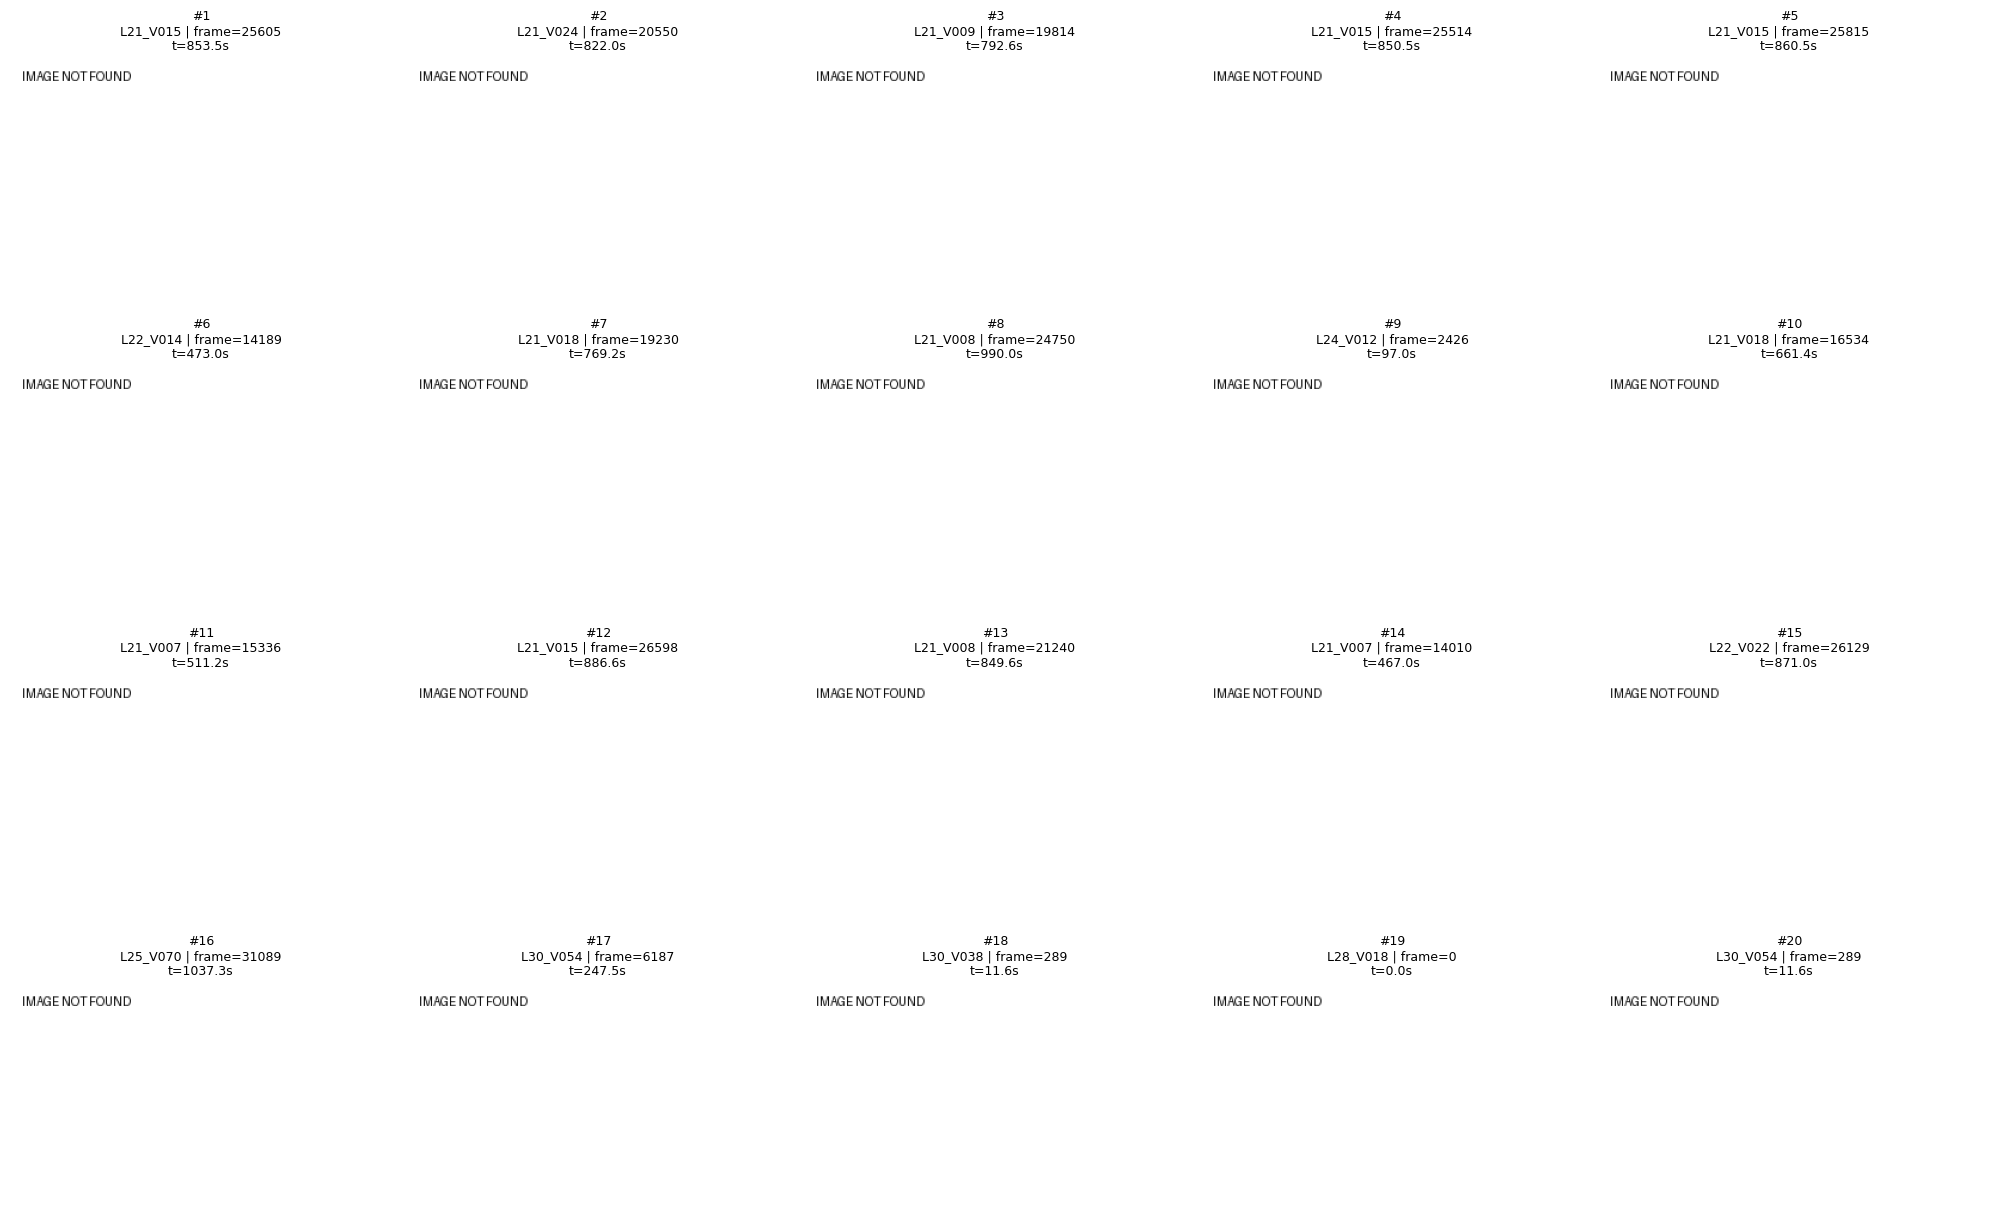


Page 2/5 | ranks 21-40


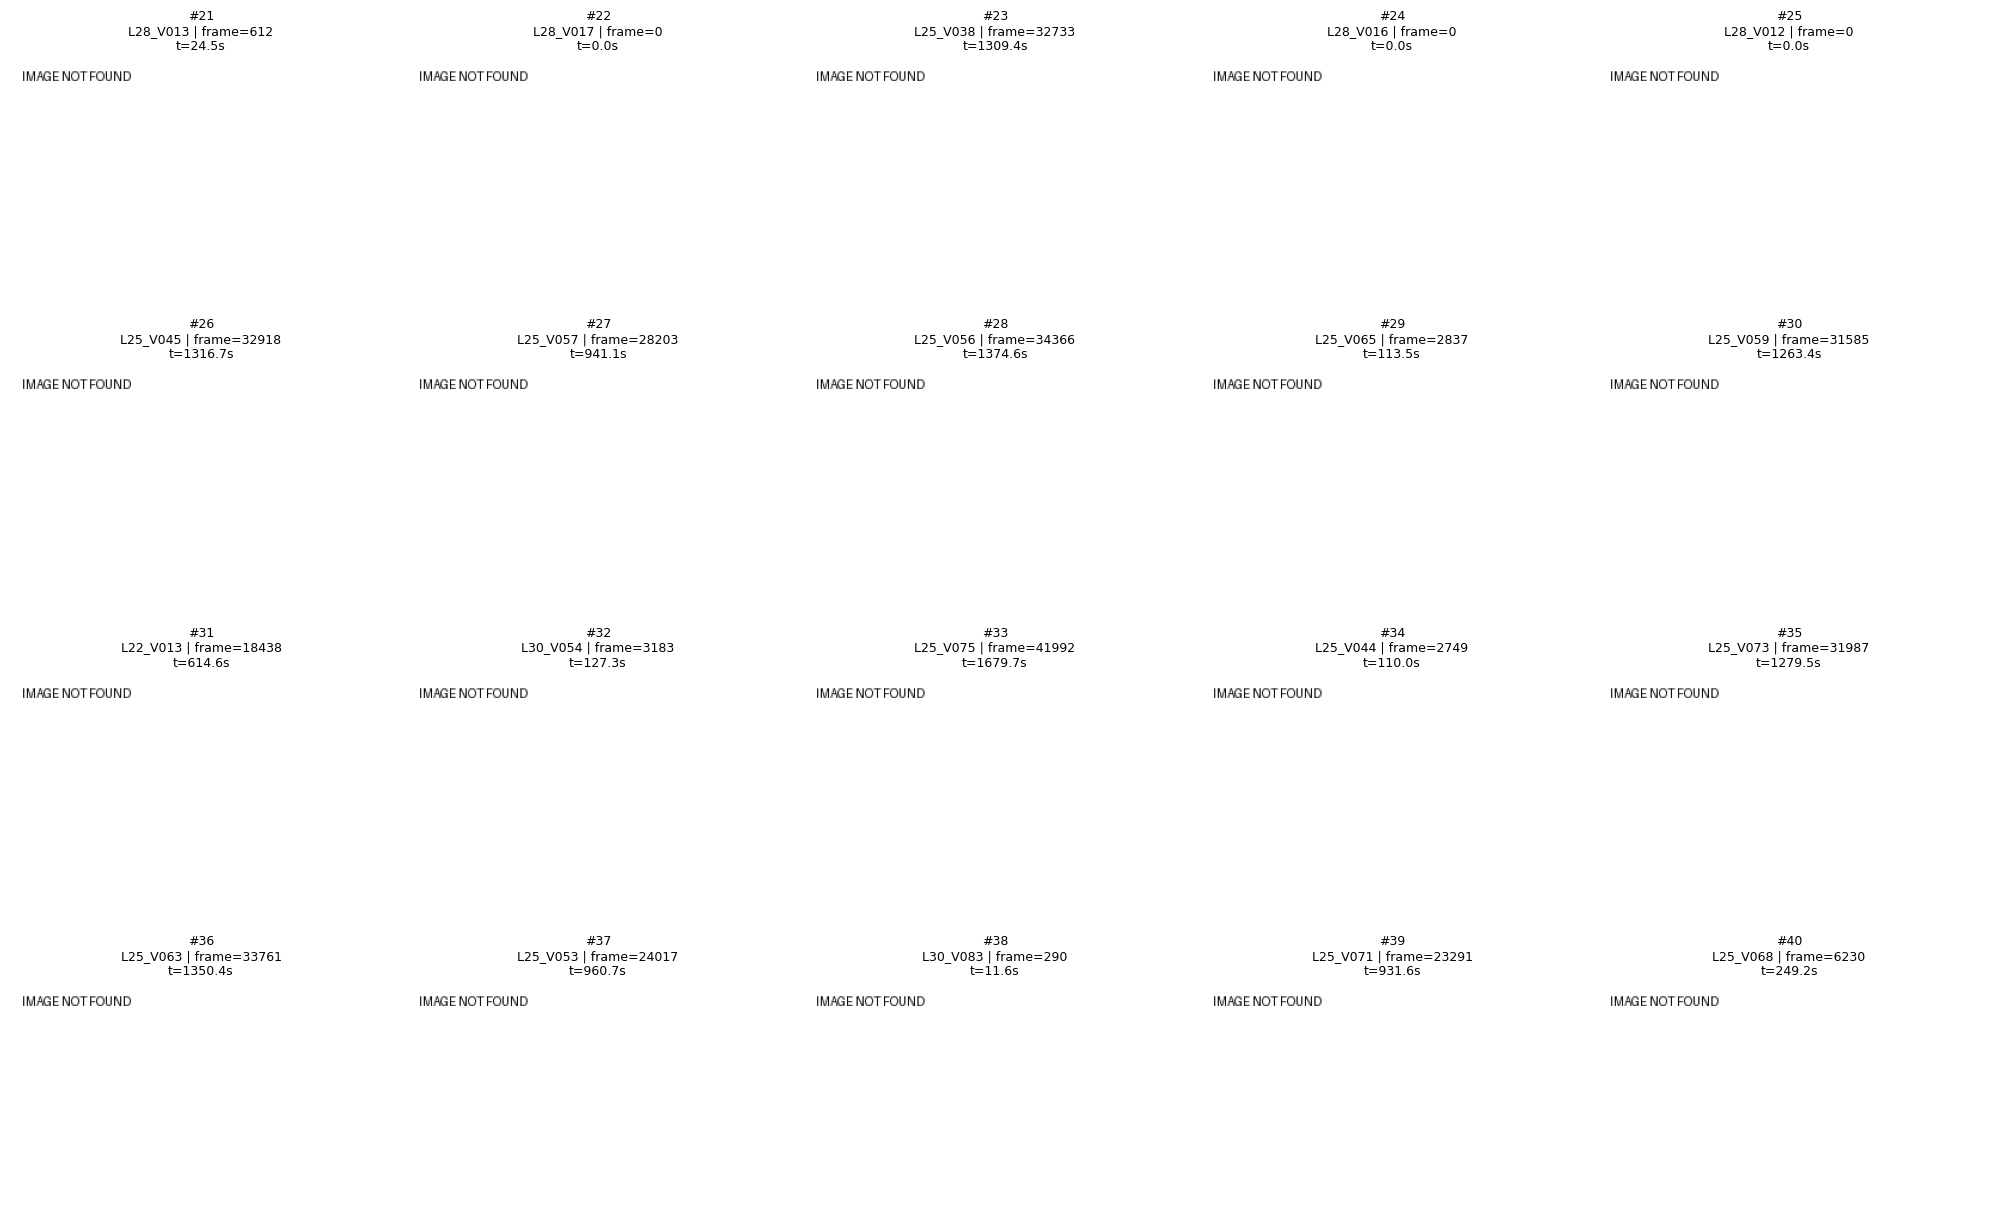


Page 3/5 | ranks 41-60


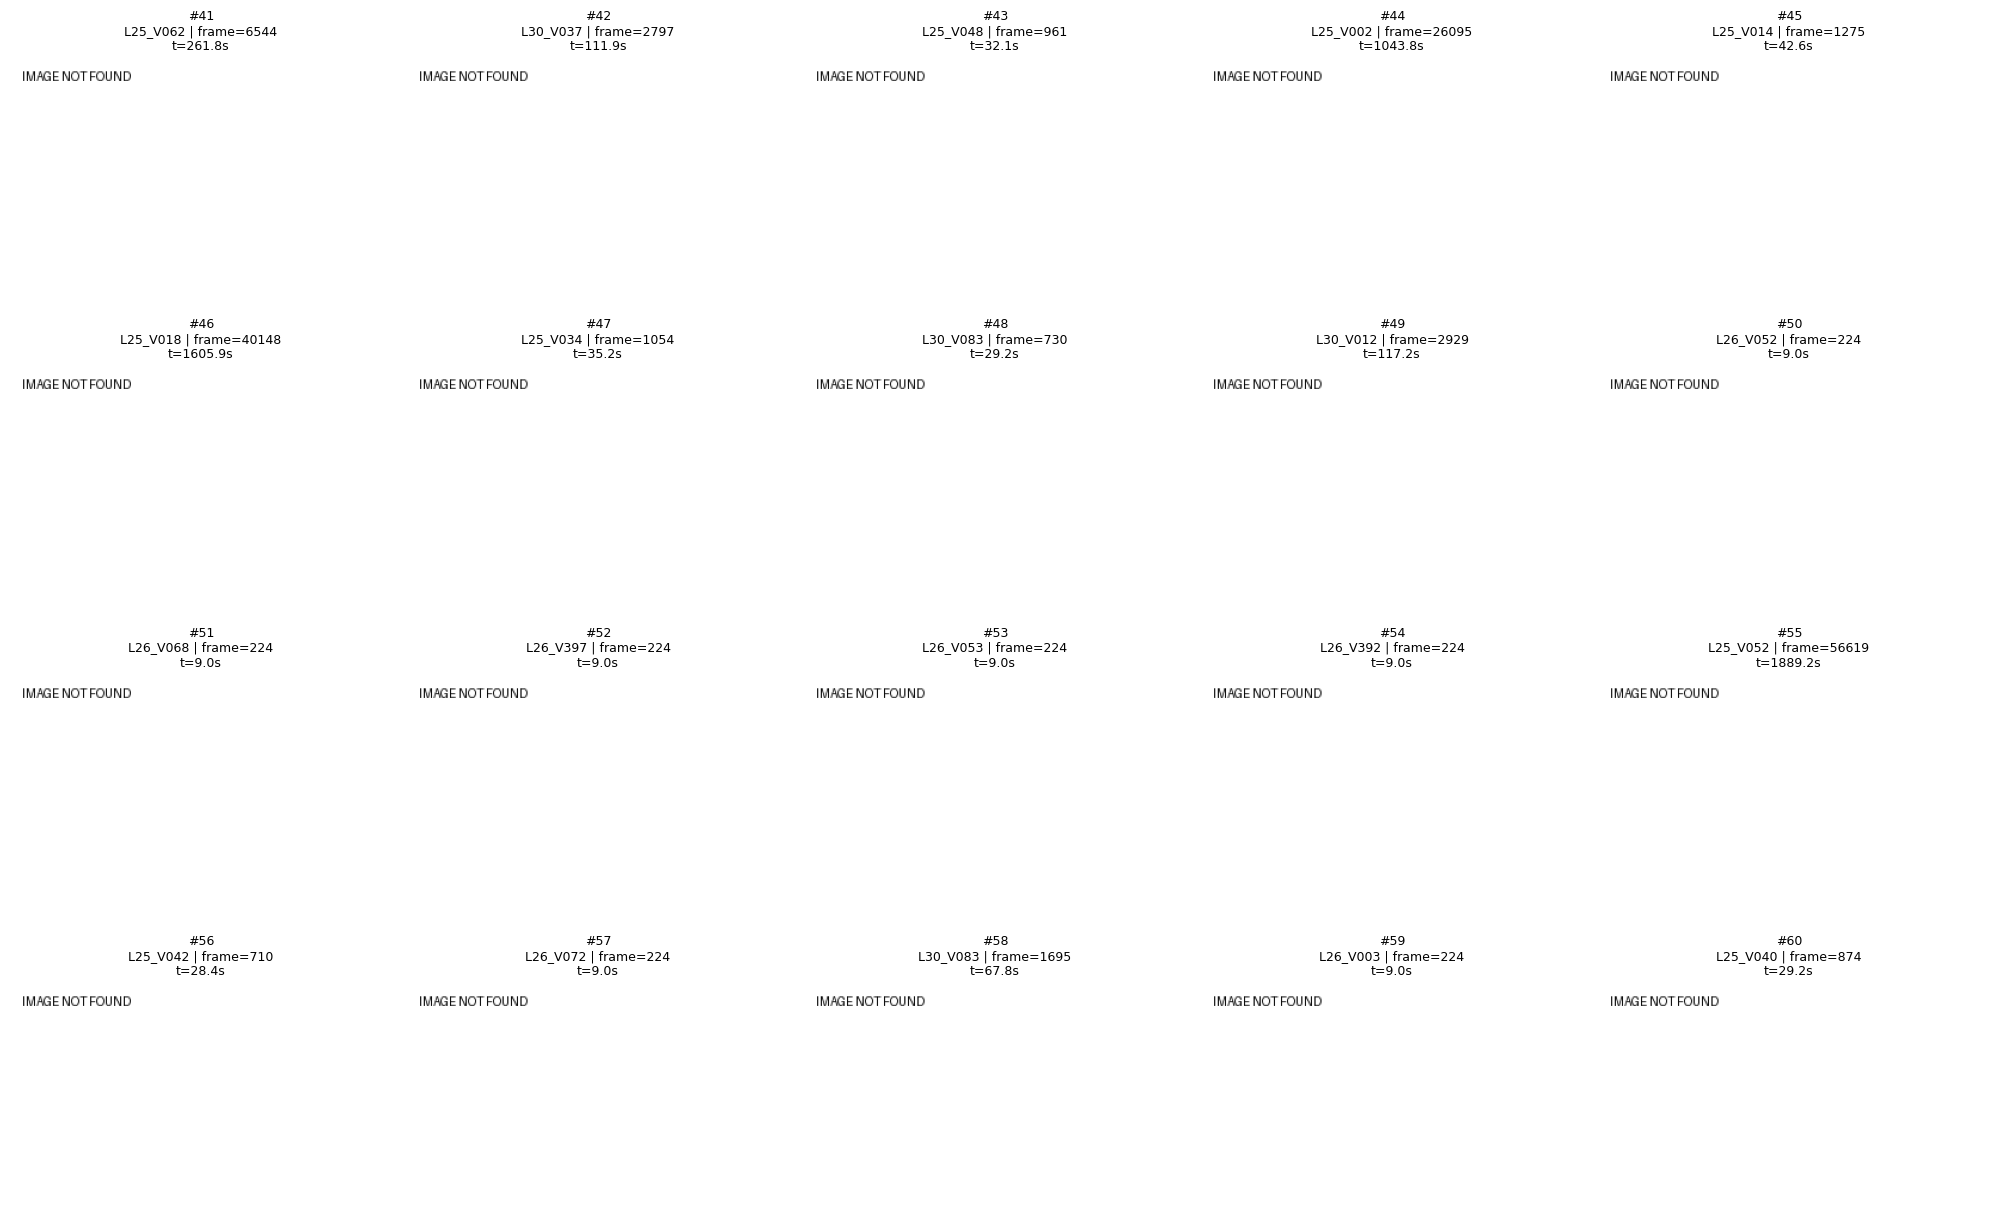


Page 4/5 | ranks 61-80


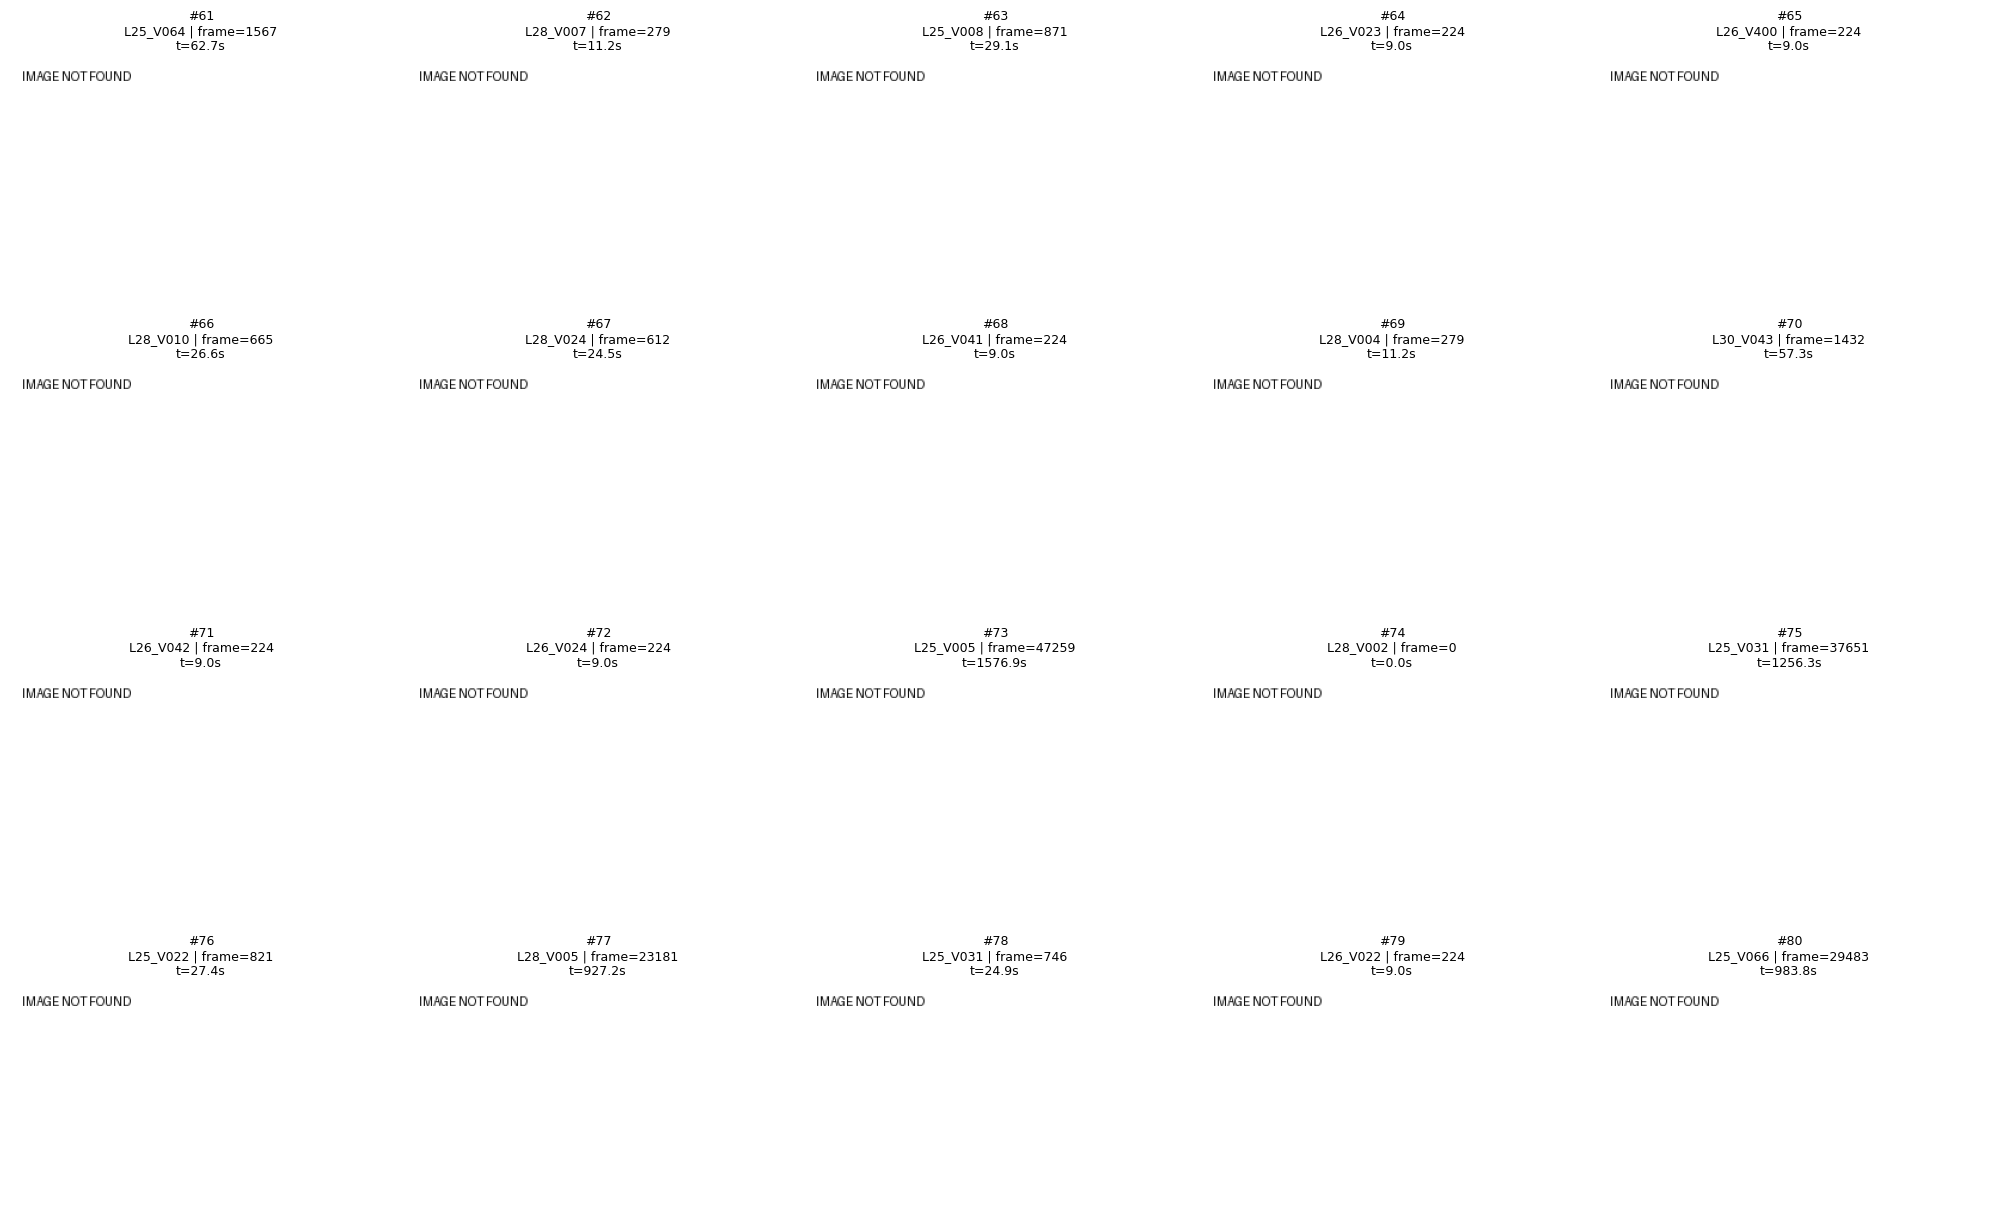


Page 5/5 | ranks 81-100


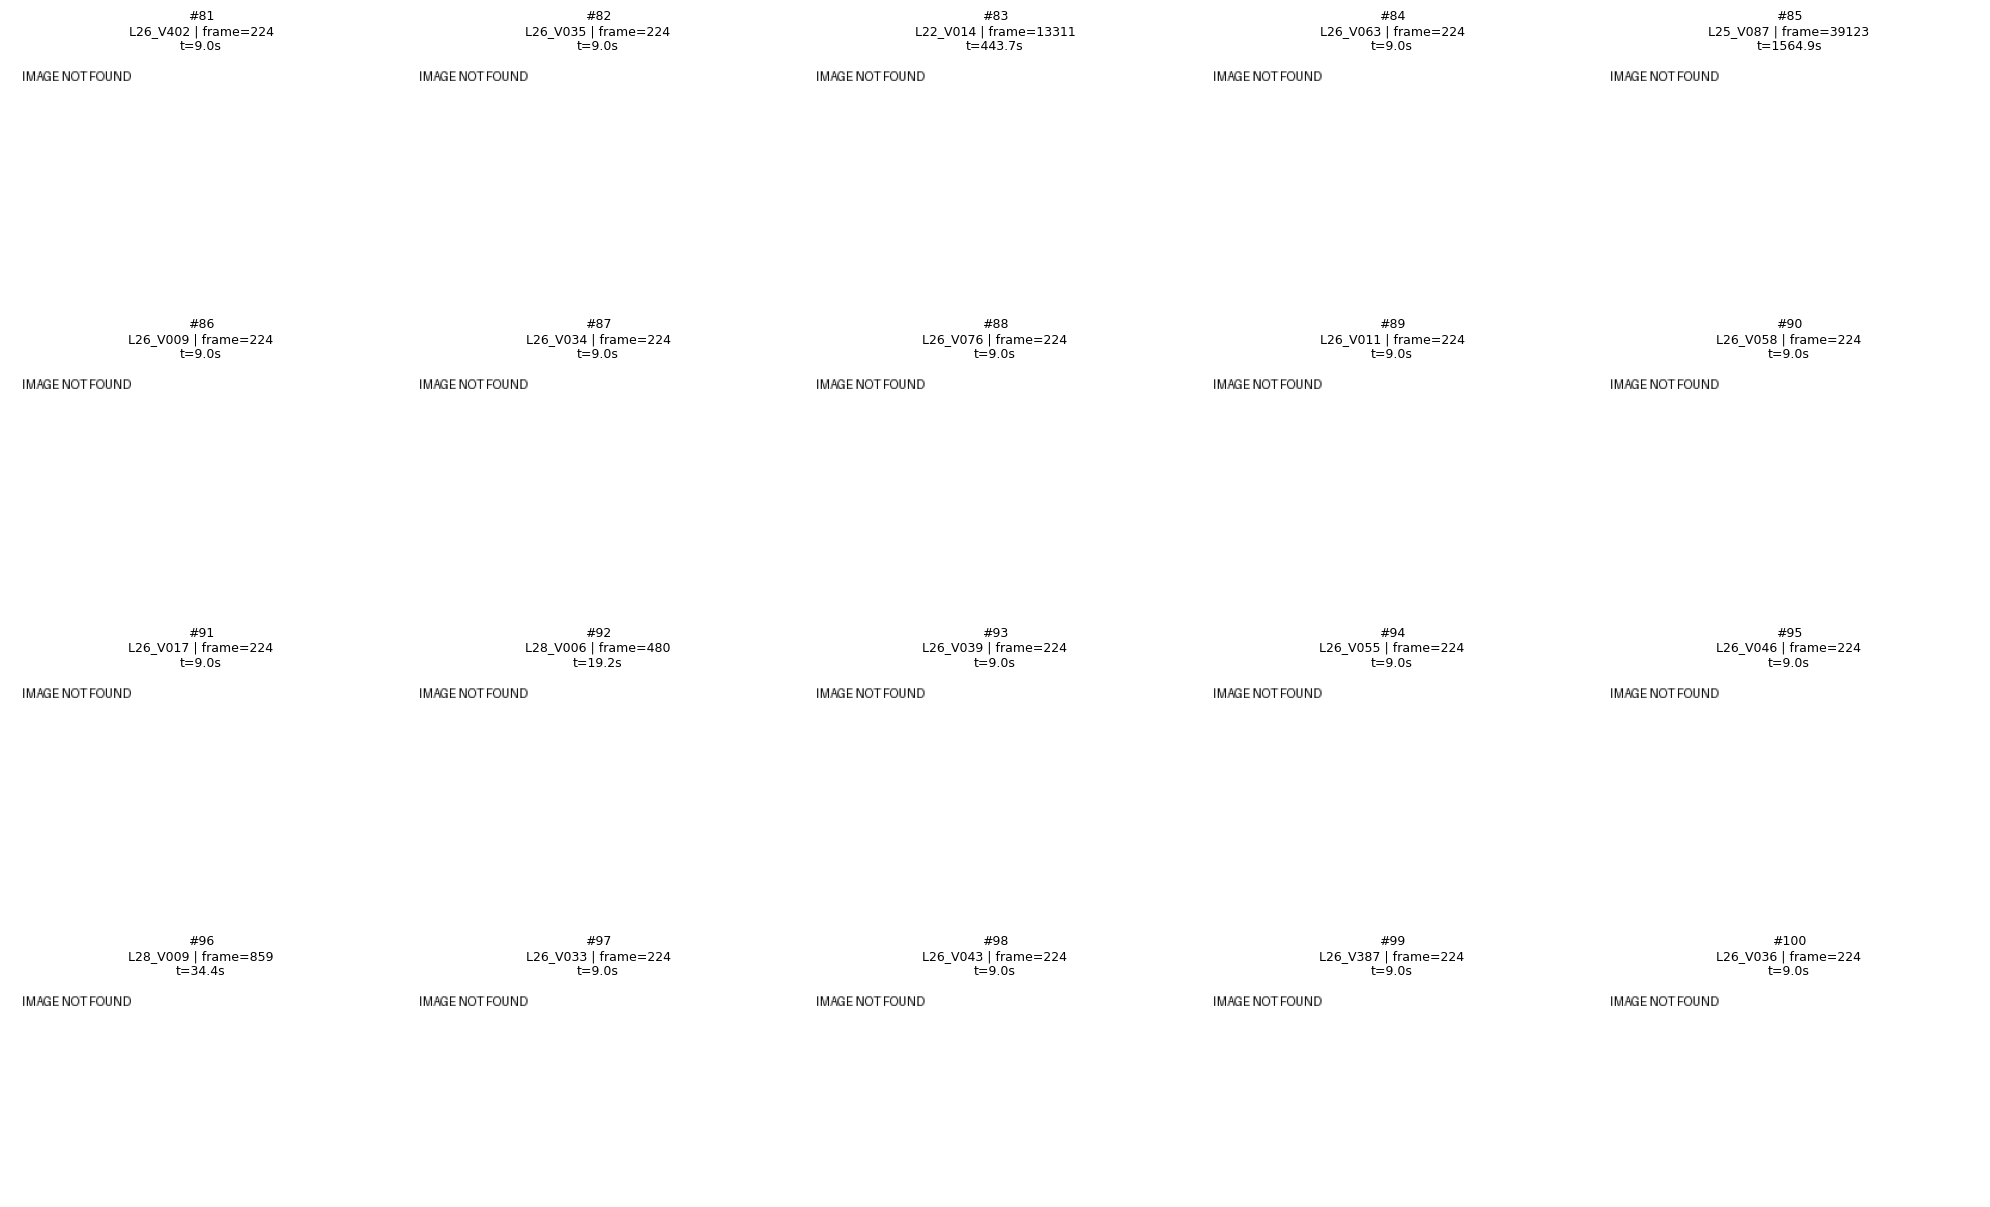

In [36]:
display_query_top100(
    pack_result,
    "query-p1-1-kis",
)

In [ ]:
queries_to_check = [
    "query-p1-1-kis",
    "query-p1-2-kis",
    "query-p1-5-kis",
    "query-p1-6-kis",
    "query-p1-7-kis",
    "query-p1-8-kis",
    "query-p1-9-kis",
    "query-p1-10-kis",
    "query-p1-11-kis",
    "query-p1-12-kis",
    "query-p1-13-kis",
    "query-p1-14-kis",
    "query-p1-17-kis",
    "query-p1-20-kis",
    "query-p1-21-kis",
    "query-p1-23-kis",
    "query-p1-24-kis",
    "query-p1-25-kis",
]

for q in queries_to_check:
    display_query_top100(
        pack_result,
        q,
        cols=5,
        rows_per_page=4,
    )

In [ ]:
# ============================================================
# 27. FINAL MANUAL INSPECTION BEFORE SUBMISSION
# ============================================================
def inspect_ready_submission(pack_result, preview_lines=8):
    zip_path = Path(pack_result['zip_local'])
    validate_submission_zip(zip_path)
    print('\nCSV previews:')
    with zipfile.ZipFile(zip_path, 'r') as zf:
        for name in sorted(n for n in zf.namelist() if n.endswith('.csv')):
            print('\n---', name, '---')
            text = zf.read(name).decode('utf-8')
            print('\n'.join(text.splitlines()[:preview_lines]))

# After running the pack:
inspect_ready_submission(pack_result)


ZIP entries:
  submission/
  submission/query-p1-1-kis.csv
  submission/query-p1-10-kis.csv
  submission/query-p1-11-kis.csv
  submission/query-p1-12-kis.csv
  submission/query-p1-13-kis.csv
  submission/query-p1-14-kis.csv
  submission/query-p1-17-kis.csv
  submission/query-p1-2-kis.csv
  submission/query-p1-20-kis.csv
  submission/query-p1-21-kis.csv
  submission/query-p1-23-kis.csv
  submission/query-p1-24-kis.csv
  submission/query-p1-25-kis.csv
  submission/query-p1-5-kis.csv
  submission/query-p1-6-kis.csv
  submission/query-p1-7-kis.csv
  submission/query-p1-8-kis.csv
  submission/query-p1-9-kis.csv
Submission ZIP validation: OK

CSV previews:

--- submission/query-p1-1-kis.csv ---
L21_V015,25605
L21_V024,20550
L21_V009,19814
L21_V015,25514
L21_V015,25815
L22_V014,14189
L21_V018,19230
L21_V008,24750

--- submission/query-p1-10-kis.csv ---
L30_V017,3079
L30_V017,6897
L30_V096,132
L30_V017,3010
L30_V017,3080
L28_V014,12772
L30_V074,563
L30_V018,2539

--- submission/query-p1-11-kis

# 28. Evaluation / ablation helper

Nếu bạn có validation ground truth dạng `video_id + frame range`, helper dưới đo việc đáp án đúng xuất hiện trong top-k. Đây là phần dùng để tune stage/weights trước khi tiêu 3 lượt nộp chính thức.


In [ ]:
# ============================================================
# 28. VALIDATION METRIC HELPER
# ============================================================
def evaluate_textual_kis_submission(df, gt_video, gt_start_frame, gt_end_frame):
    hits = [
        int(str(r.video_id) == str(gt_video) and int(gt_start_frame) <= int(r.frame_idx) <= int(gt_end_frame))
        for r in df.itertuples(index=False)
    ]
    metrics = {}
    for k in [1, 5, 20, 50, 100]:
        metrics[f'R@{k}'] = max(hits[:k], default=0)
    metrics['MeanRecallAtK'] = float(np.mean([metrics[f'R@{k}'] for k in [1,5,20,50,100]]))
    return metrics

# Example:
# evaluate_textual_kis_submission(one['submission'], 'L01_V001', 500, 530)


# 29. Recommended ablation order

Đừng tune tất cả cùng lúc. Với một validation set riêng, so sánh lần lượt:

1. `BASE_QWEN`: single/multi-view dense retrieval plumbing baseline.
2. Query parser + multi-query weighted RRF.
3. + Faster R-CNN base object evidence.
4. + lexical/BM25 evidence.
5. + Grounding DINO.
6. + temporal grouping.
7. + Qwen3-VL-Reranker-2B.
8. + lazy OCR trên các query thật sự cần chữ/logo/số.
9. Tune `PRE_RERANK_WEIGHTS`, `TEMPORAL_GAP_SECONDS`, `EXPENSIVE_VERIFY_TOPK`, `RERANK_TOP_SEGMENTS`.
10. Tune Top-100 temporal hedge/diversity theo metric cuộc thi.

## Important operational notes

- Không sửa/reorder `master_keyframes.parquet` sau khi FAISS đã build.
- Query encoder luôn dùng cùng model, 1024D prefix, L2 normalization và retrieval instruction với corpus embedding.
- `frame_idx` mới là frame thật dùng để submission; `keyframe_id` chỉ dùng nội bộ.
- `Grounding DINO`/OCR/reranker chỉ đọc candidate images; không cần copy toàn bộ keyframes sang `/content`.
- Sau khi đã chọn cấu hình để nộp, chạy **cell 25 + 27** trước khi upload ZIP lên hệ thống.


In [ ]:
# ============================================================
# 30. OPTIONAL RESOURCE CLEANUP
# ============================================================
def cleanup_expensive_models(clear_local_images=False):
    unload_parser()
    unload_grounding()
    unload_reranker()
    global _ocr_reader
    _ocr_reader = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if clear_local_images and LOCAL_IMAGE_CACHE.exists():
        shutil.rmtree(LOCAL_IMAGE_CACHE)
        LOCAL_IMAGE_CACHE.mkdir(parents=True, exist_ok=True)
    print('Cleanup complete.')

# cleanup_expensive_models(clear_local_images=False)
